In [5]:
# from google.colab import drive
# drive.mount('/content/drive') 

In [6]:
#Data preprocessing
import numpy as np
import pandas as pd
import warnings # to ignore warnings
warnings.filterwarnings('ignore')
import random, re
import math

#Data visualisation 
import plotly.express as express
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
from wordcloud import WordCloud, STOPWORDS

from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, recall_score, precision_score, roc_auc_score
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# cross-validation methods
from sklearn.model_selection import KFold
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import VotingClassifier
# pre-processing methods
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
# Deep learning libraries
from tensorflow import keras
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Activation
from tensorflow.keras import regularizers, optimizers
from sklearn.metrics import r2_score
from tensorflow.keras.models import load_model
from tensorflow.keras.layers import BatchNormalization
from keras.utils import np_utils
from keras.layers import Input
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.models import Sequential
from tensorflow.keras import optimizers
from keras.models import Model
from keras.layers.merge import Concatenate
from tensorflow.keras.layers import Flatten, Activation, Dense, LSTM, BatchNormalization, Embedding, Dropout, Flatten, Bidirectional, GlobalMaxPool1D
from keras.models import model_from_json
from keras.regularizers import l1, l2, l1_l2
from keras.constraints import maxnorm, min_max_norm
from keras.constraints import unit_norm
from keras.callbacks import ReduceLROnPlateau
from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint
from keras.models import model_from_json
from keras.models import load_model
from keras.wrappers.scikit_learn import KerasClassifier
from sklearn.naive_bayes import MultinomialNB,GaussianNB
# Keras pre-processing
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import nltk
from nltk.util import ngrams
nltk.download('vader_lexicon')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
import string
nltk.download('stopwords')
import string
from nltk.tokenize import word_tokenize
from tqdm import tqdm
from nltk.corpus import stopwords
from nltk import tokenize,stem
from gensim import models
from gensim.models import Word2Vec
from wordcloud import WordCloud, STOPWORDS

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/padda/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/padda/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/padda/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/padda/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/padda/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Importing Data Sets

In [7]:
# file_path = '/content/drive/MyDrive/GreatLearning_Capstone_Group10/Dataset/'

In [8]:
safety_data = pd.read_csv("IHMStefanini_industrial_safety_and_health_database_with_accidents_description.csv")

In [9]:
#Validate the dataset information
safety_data.head(5)

,Unnamed: 0,Data,Countries,Local,Industry Sector,Accident Level,Potential Accident Level,Genre,Employee or Third Party,Critical Risk,Description
0,0,2016-01-01 00:00:00,Country_01,Local_01,Mining,I,IV,Male,Third Party,Pressed,While removing the drill rod of the Jumbo 08 f...
1,1,2016-01-02 00:00:00,Country_02,Local_02,Mining,I,IV,Male,Employee,Pressurized Systems,During the activation of a sodium sulphide pum...
2,2,2016-01-06 00:00:00,Country_01,Local_03,Mining,I,III,Male,Third Party (Remote),Manual Tools,In the sub-station MILPO located at level +170...
3,3,2016-01-08 00:00:00,Country_01,Local_04,Mining,I,I,Male,Third Party,Others,Being 9:45 am. approximately in the Nv. 1880 C...
4,4,2016-01-10 00:00:00,Country_01,Local_04,Mining,IV,IV,Male,Third Party,Others,Approximately at 11:45 a.m. in circumstances t...


In [10]:
#Check the shape of the dataset
print(f'Shape of the industrial safety dataset: {safety_data.shape}')

Shape of the industrial safety dataset: (425, 11)


In [11]:
safety_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Unnamed: 0                425 non-null    int64 
 1   Data                      425 non-null    object
 2   Countries                 425 non-null    object
 3   Local                     425 non-null    object
 4   Industry Sector           425 non-null    object
 5   Accident Level            425 non-null    object
 6   Potential Accident Level  425 non-null    object
 7   Genre                     425 non-null    object
 8   Employee or Third Party   425 non-null    object
 9   Critical Risk             425 non-null    object
 10  Description               425 non-null    object
dtypes: int64(1), object(10)
memory usage: 36.6+ KB


### Observations:
* We can see categorical information in the columns other than Data column
* Both the datasets (1)"IHMStefanini_industrial_safety_and_health_database.csv" and  (2) "IHMStefanini_industrial_safety_and_health_database_with_accidents_description.csv" contain similar data with (2) having discriptions of the accidents as well.   

In [12]:
safety_data['Accident Level'].value_counts()

I      316
II      40
III     31
IV      30
V        8
Name: Accident Level, dtype: int64

## Perform Data Cleansing

In [13]:
#check for null values
safety_data.isna().sum()

Unnamed: 0                  0
Data                        0
Countries                   0
Local                       0
Industry Sector             0
Accident Level              0
Potential Accident Level    0
Genre                       0
Employee or Third Party     0
Critical Risk               0
Description                 0
dtype: int64


*We can see that there are 0 null values in the dataset*

In [14]:
#check for duplicate values
print(f'There are {safety_data.duplicated().sum()} duplicate values in the dataset')

There are 0 duplicate values in the dataset


In [15]:
#Rename the column names
safety_data.rename(columns={'Data': 'Date', 'Countries': 'Country', 'Genre':'Gender','Employee or Third Party':'Employee Category' }
                   , inplace = True)
#Drop unwanted columns
safety_data.drop(columns=('Unnamed: 0'), inplace = True, axis =1)

In [16]:
#Validate the columns after cleanup
safety_data.head()

,Date,Country,Local,Industry Sector,Accident Level,Potential Accident Level,Gender,Employee Category,Critical Risk,Description
0,2016-01-01 00:00:00,Country_01,Local_01,Mining,I,IV,Male,Third Party,Pressed,While removing the drill rod of the Jumbo 08 f...
1,2016-01-02 00:00:00,Country_02,Local_02,Mining,I,IV,Male,Employee,Pressurized Systems,During the activation of a sodium sulphide pum...
2,2016-01-06 00:00:00,Country_01,Local_03,Mining,I,III,Male,Third Party (Remote),Manual Tools,In the sub-station MILPO located at level +170...
3,2016-01-08 00:00:00,Country_01,Local_04,Mining,I,I,Male,Third Party,Others,Being 9:45 am. approximately in the Nv. 1880 C...
4,2016-01-10 00:00:00,Country_01,Local_04,Mining,IV,IV,Male,Third Party,Others,Approximately at 11:45 a.m. in circumstances t...


In [17]:
#checking for unique values of each categorical columns 
for x in safety_data.columns:
    if x != 'Description':
      print('---'*25); print(f'Unique values of "{x}" column'); print('---'*25)
      print(safety_data[x].unique())
      print('\n')

---------------------------------------------------------------------------
Unique values of "Date" column
---------------------------------------------------------------------------
['2016-01-01 00:00:00' '2016-01-02 00:00:00' '2016-01-06 00:00:00'
 '2016-01-08 00:00:00' '2016-01-10 00:00:00' '2016-01-12 00:00:00'
 '2016-01-16 00:00:00' '2016-01-17 00:00:00' '2016-01-19 00:00:00'
 '2016-01-26 00:00:00' '2016-01-28 00:00:00' '2016-01-30 00:00:00'
 '2016-02-01 00:00:00' '2016-02-02 00:00:00' '2016-02-04 00:00:00'
 '2016-02-06 00:00:00' '2016-02-07 00:00:00' '2016-02-08 00:00:00'
 '2016-02-21 00:00:00' '2016-02-25 00:00:00' '2016-02-09 00:00:00'
 '2016-02-10 00:00:00' '2016-02-15 00:00:00' '2016-02-14 00:00:00'
 '2016-02-13 00:00:00' '2016-02-16 00:00:00' '2016-02-17 00:00:00'
 '2016-02-19 00:00:00' '2016-02-20 00:00:00' '2016-02-18 00:00:00'
 '2016-02-22 00:00:00' '2016-02-24 00:00:00' '2016-02-29 00:00:00'
 '2016-02-26 00:00:00' '2016-02-27 00:00:00' '2016-03-02 00:00:00'
 '2016-03-03 

### Observations:
* There are no NULL values that needs to fixed. 

### Data Pre-processing and Analysis

In [18]:
# function to classify the month to appropriate Season. Considering the factories are in South America, 
# the factories would see 4 months as decribed below
def month2seasons(x):
    if x in [9, 10, 11]:
        season = 'Spring'
    elif x in [12, 1, 2]:
        season = 'Summer'
    elif x in [3, 4, 5]:
        season = 'Autumn'
    elif x in [6, 7, 8]:
        season = 'Winter'
    return season


# To understand the dataset better the date column into day, month, year, weekday, weekoftheyear
safety_data['Date'] = pd.to_datetime(safety_data['Date'])

safety_data['Year'] = safety_data.Date.apply(lambda x : x.year)
safety_data['Month'] = safety_data.Date.apply(lambda x : x.month)
safety_data['Day'] = safety_data.Date.apply(lambda x : x.day)
safety_data['Weekday'] = safety_data.Date.apply(lambda x : x.day_name())
safety_data['WeekofYear'] = safety_data.Date.apply(lambda x : x.weekofyear)

#Assign Seasons to rows
safety_data['Season'] = safety_data['Month'].apply(month2seasons)

In [19]:

safety_data.head(5)

,Date,Country,Local,Industry Sector,Accident Level,Potential Accident Level,Gender,Employee Category,Critical Risk,Description,Year,Month,Day,Weekday,WeekofYear,Season
0,2016-01-01,Country_01,Local_01,Mining,I,IV,Male,Third Party,Pressed,While removing the drill rod of the Jumbo 08 f...,2016,1,1,Friday,53,Summer
1,2016-01-02,Country_02,Local_02,Mining,I,IV,Male,Employee,Pressurized Systems,During the activation of a sodium sulphide pum...,2016,1,2,Saturday,53,Summer
2,2016-01-06,Country_01,Local_03,Mining,I,III,Male,Third Party (Remote),Manual Tools,In the sub-station MILPO located at level +170...,2016,1,6,Wednesday,1,Summer
3,2016-01-08,Country_01,Local_04,Mining,I,I,Male,Third Party,Others,Being 9:45 am. approximately in the Nv. 1880 C...,2016,1,8,Friday,1,Summer
4,2016-01-10,Country_01,Local_04,Mining,IV,IV,Male,Third Party,Others,Approximately at 11:45 a.m. in circumstances t...,2016,1,10,Sunday,1,Summer


# EDA

## Univariate Analysis

In [20]:
def plot(col, title):

    value = safety_data[col].value_counts()[1]
    plt.figure(figsize = (15,12))
    plt.subplot(2,2,1)
    sns.countplot(data = safety_data, x=safety_data[col]);
    plt.title(title);

    plt.subplot(2,2,2)

    plt.pie(safety_data[col].value_counts(), autopct = "%.2f",
       labels = safety_data[col].value_counts().index , shadow = True, explode = [0.1]*len(safety_data[col].value_counts().index));
    plt.title(title);
    plt.show()

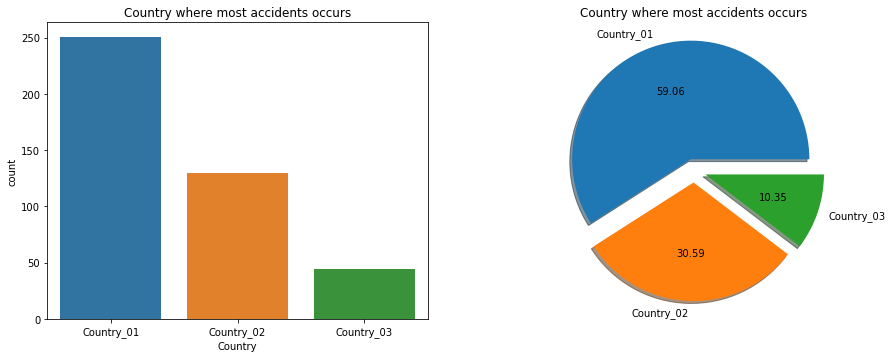

In [21]:
plot('Country','Country where most accidents occurs')

### Industry Sector

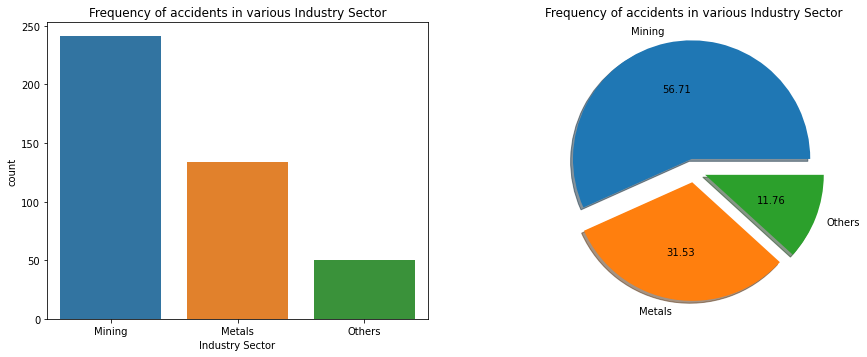

In [22]:
# Frequency of accidents in various Industry Sector
plot('Industry Sector','Frequency of accidents in various Industry Sector') 

### Employee Category

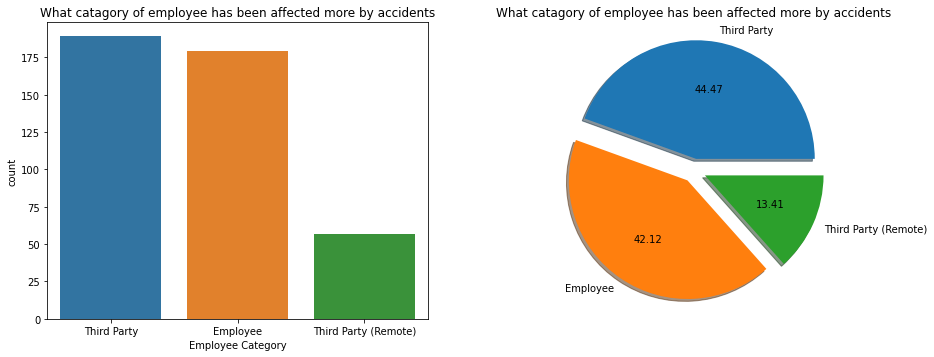

In [23]:
### Category of employee affected by the accidents
plot('Employee Category','What catagory of employee has been affected more by accidents')

### Gender

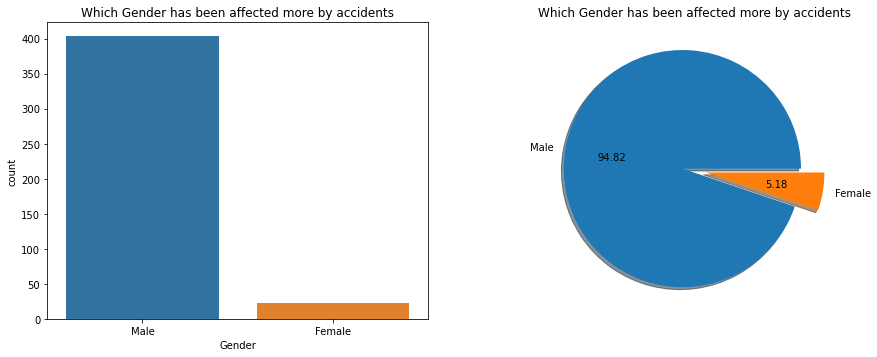

In [24]:
plot('Gender', 'Which Gender has been affected more by accidents')

### Accident Level

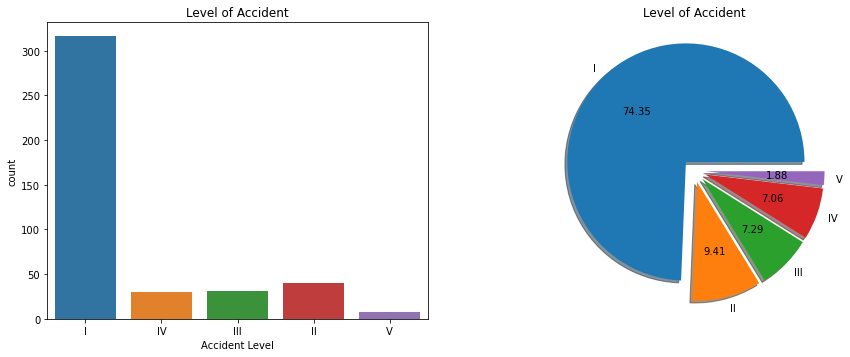

In [25]:
plot('Accident Level', 'Level of Accident')

### Potential Accident Level

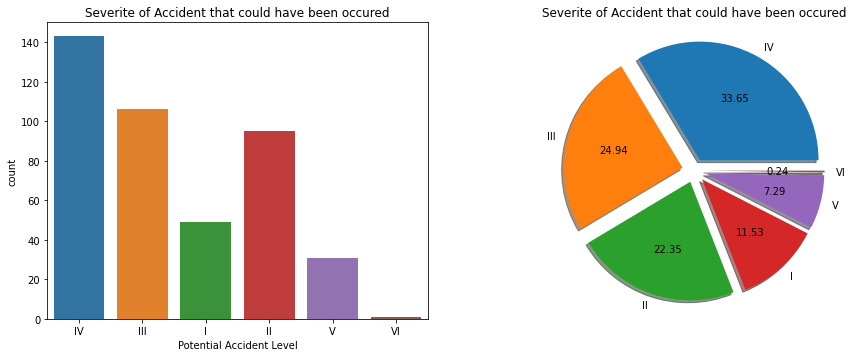

In [26]:
plot('Potential Accident Level', 'Severite of Accident that could have been occured')

### Local

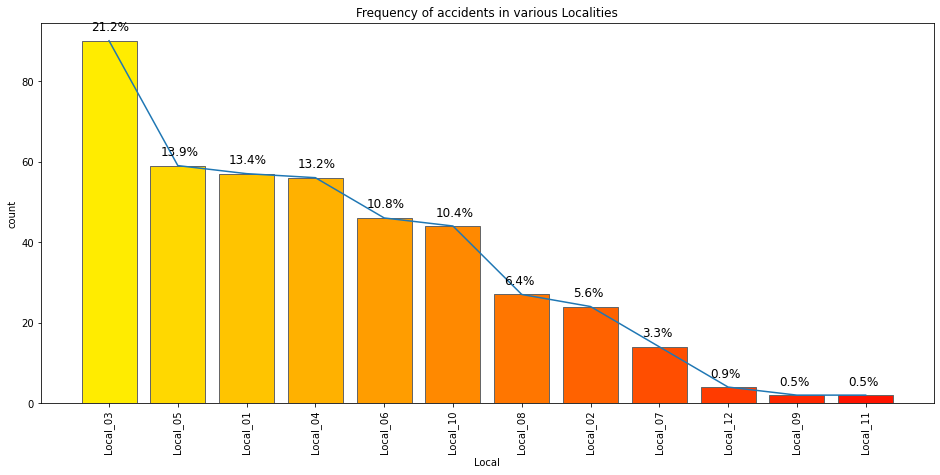

In [27]:
# Locals Count
plt.figure(figsize = (16,7))
ax = sns.countplot(x = safety_data['Local'], order=safety_data['Local'].value_counts().index, palette = 'autumn_r', edgecolor='.4', saturation=1);
sns.lineplot(safety_data['Local'].value_counts().index, safety_data['Local'].value_counts().values)

plt.title('Frequency of accidents in various Localities');
plt.xticks(rotation = 'vertical');

total = sum(safety_data['Local'].value_counts())
for p in ax.patches:
    ax.annotate('{:.1f}%'.format(100*p.get_height()/total), 
                (p.get_x(), p.get_height()),
                 size=12,
                 xytext = (10, 10), 
                 textcoords = 'offset points')

### Critical Risk

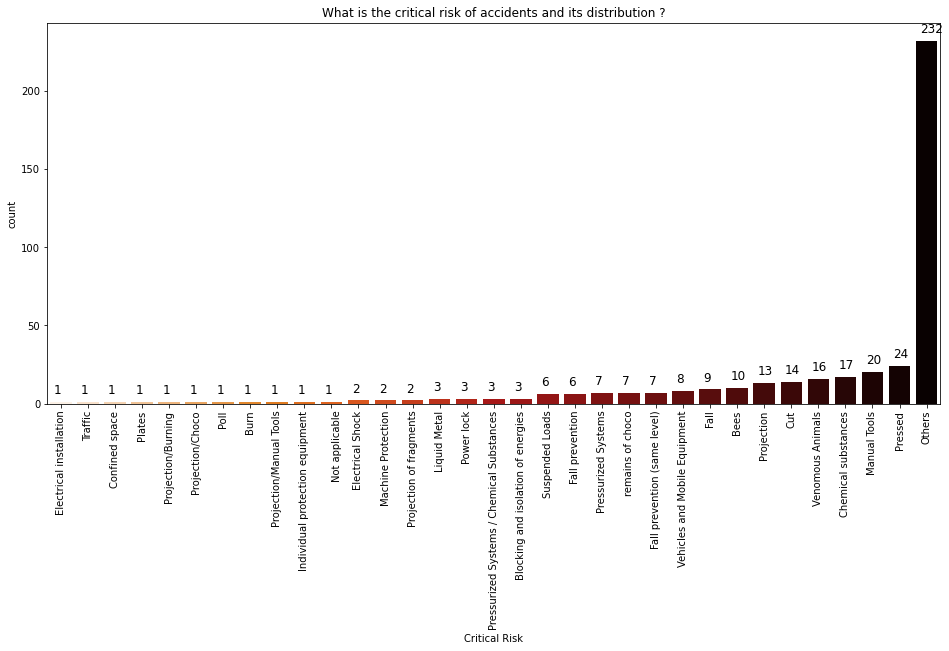

In [28]:
# Critical Risk Count
plt.figure(figsize = (16,7))
ax = sns.countplot(x = safety_data['Critical Risk'], order=safety_data['Critical Risk'].value_counts().sort_values(ascending = True).index, palette = 'gist_heat_r');
plt.title('What is the critical risk of accidents and its distribution ?');
plt.xticks(rotation = 'vertical');

total = sum(safety_data['Critical Risk'].value_counts())
for p in ax.patches:
    ax.annotate('{}'.format(p.get_height()), 
                (p.get_x(), p.get_height()),
                 size=12,
                 xytext = (4, 8), 
                 textcoords = 'offset points')

### Season

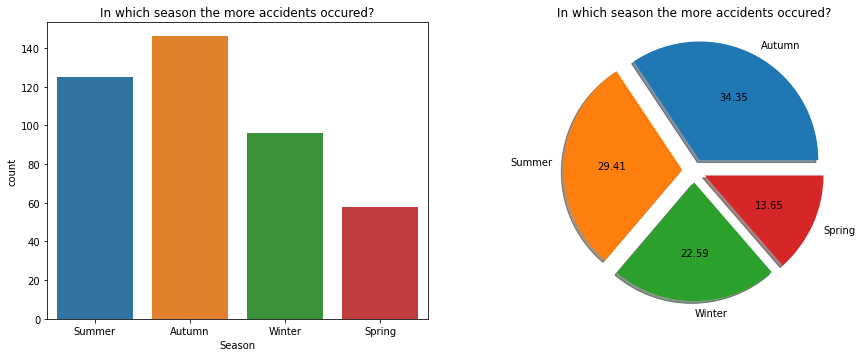

In [29]:
plot('Season', 'In which season the more accidents occured?')

### Calendar

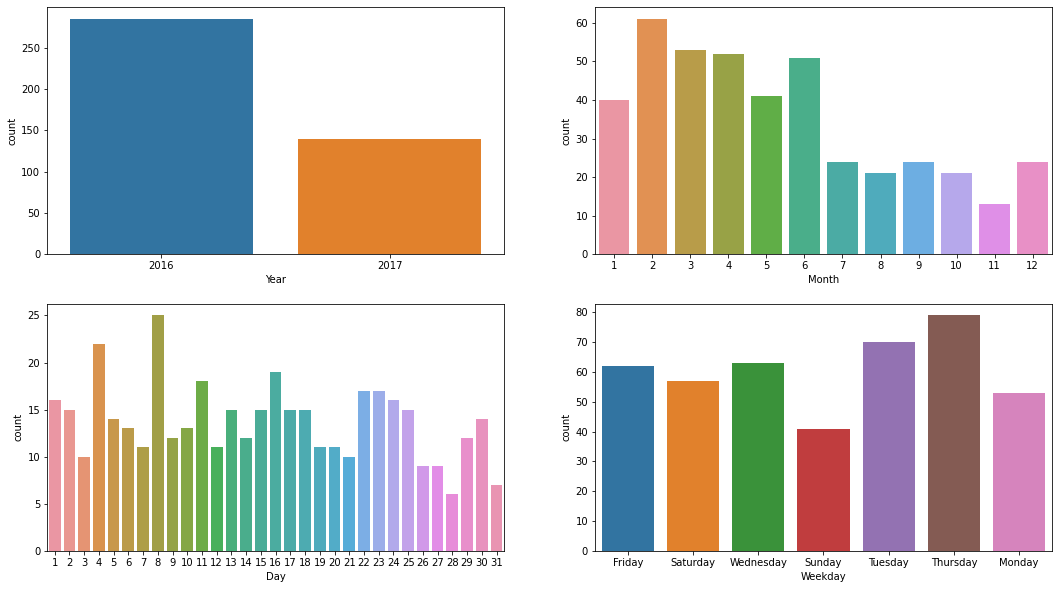

In [30]:
fig,ax = plt.subplots(2, 2, figsize=(18, 10))
sns.countplot(safety_data['Year'], ax=ax[0,0])
sns.countplot(safety_data['Month'], ax=ax[0,1])
sns.countplot(safety_data['Day'], ax=ax[1,0])
sns.countplot(safety_data['Weekday'], ax=ax[1,1])
fig.show()

In [31]:
###function to calculate top 30 ngram under several conditions
def ngram_func(ngram, trg='', trg_value=''):
    #trg_value is list-object
    if (trg == '') or (trg_value == ''):
        string_filterd =  safety_data['Description'].sum().split()
    else:
        string_filterd =  safety_data[safety_data[trg].isin(trg_value)]['Description'].sum().split()
    dic = nltk.FreqDist(nltk.ngrams(string_filterd, ngram)).most_common(30)
    ngram_safety_data = pd.DataFrame(dic, columns=['ngram','count'])
    ngram_safety_data['ngrams'] = [' '.join(i) for i in ngram_safety_data.ngram]
    ngram_safety_data.drop('ngram',axis=1, inplace=True)
    return ngram_safety_data

### Unigram

In [32]:
data = ngram_func(1)[::-1]
data = data.sort_values('count', ascending=False)
fig = express.bar (data, x='ngrams',y='count')
fig.show()

### Bigram

In [33]:
data = ngram_func(2)[::-1]
data = data.sort_values('count', ascending=False)
fig = express.bar (data, x='ngrams',y='count')
fig.show()

### Trigram

In [34]:
data = ngram_func(3)[::-1]
data = data.sort_values('count', ascending=False)
fig = express.bar (data, x='ngrams',y='count')
fig.show()

In [35]:
import re
import unicodedata
import nltk
from nltk.corpus import stopwords
nltk.download('wordnet')
# add appropriate words that will be ignored in the analysis
ADDITIONAL_STOPWORDS = ['covfefe']

import matplotlib.pyplot as plt
def basic_clean(text):
  """
  A simple function to clean up the data. All the words that
  are not designated as a stop word is then lemmatized after
  encoding and basic regex parsing are performed.
  """
  wnl = nltk.stem.WordNetLemmatizer()
  stopwords = nltk.corpus.stopwords.words('english') + ADDITIONAL_STOPWORDS
  text = (unicodedata.normalize('NFKD', text)
    .encode('ascii', 'ignore')
    .decode('utf-8', 'ignore')
    .lower())
  words = re.sub(r'[^\w\s]', '', text).split()
  return [wnl.lemmatize(word) for word in words if word not in stopwords]

[nltk_data] Downloading package wordnet to /Users/padda/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [36]:
words = basic_clean(''.join(str(safety_data['Description'].tolist())))

<AxesSubplot:>

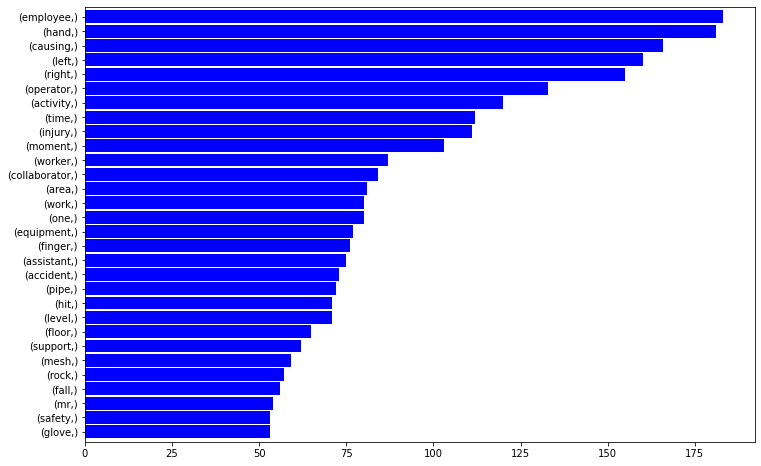

In [37]:
uni_gram=(pd.Series(nltk.ngrams(words, 1)).value_counts())[:30]
uni_gram.sort_values().plot.barh(color='blue', width=.9, figsize=(12, 8))


<AxesSubplot:>

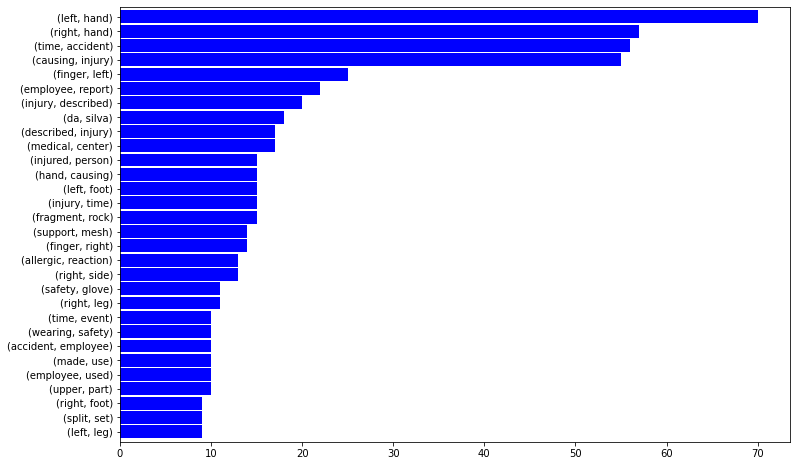

In [38]:
bi_gram=(pd.Series(nltk.ngrams(words, 2)).value_counts())[:30]
bi_gram.sort_values().plot.barh(color='blue', width=.9, figsize=(12, 8))

<AxesSubplot:>

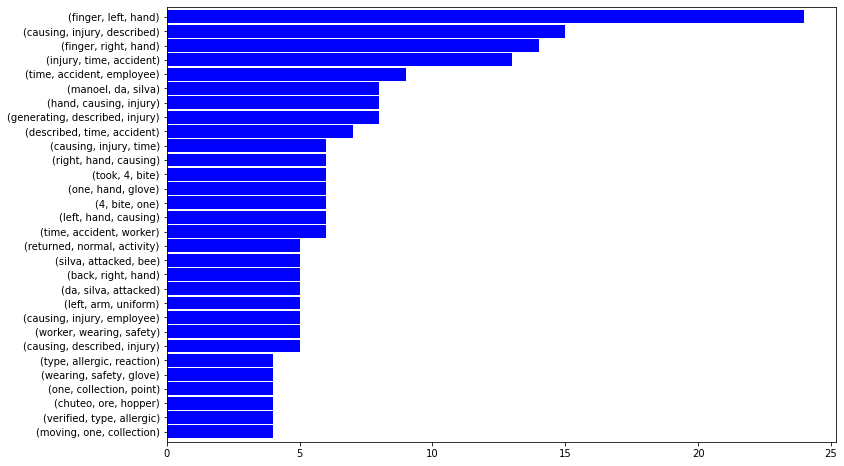

In [39]:
tri_gram=(pd.Series(nltk.ngrams(words, 3)).value_counts())[:30]
tri_gram.sort_values().plot.barh(color='blue', width=.9, figsize=(12, 8))

## Multivariate Analysis

### Accident Levels and Local by Gender

In [40]:
fig = express.imshow(pd.crosstab(safety_data['Country'],safety_data['Industry Sector']),
                   color_continuous_scale='RdBu_r')
fig.show()

In [41]:
# Relationship between Countries and Local
data = safety_data.groupby(['Country','Local']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar(data, x='Country',y='count', color='Local')
fig.show()

#### Observation
* Mining sector sees most of accidents
* Country 
** Country_01 sees the most accidents in Mining sector (203). Its also highest among all other sectors across all countries
** Country_02 sees most Metal sector accidents. 
** Country_03 see most Other sector accidents
*Local
** Local_03 (Country_01) has the most number of accidents
** Local_05 (Country_02) sees the second most accidents followed by Local_01(Country_01) and Local_10(Country_03)

<AxesSubplot:title={'center':'Potential Accident Level based on the Gender'}, xlabel='Gender', ylabel='count'>

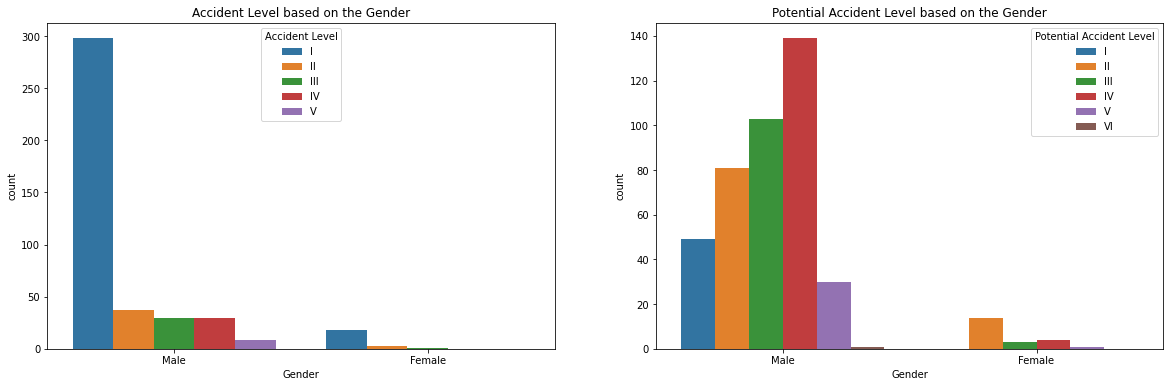

In [42]:
##Accident Levels and Potential Accident Levels by Gender
plt.figure(figsize=(20,6))
plt.subplot(1,2,1)
plt.title("Accident Level based on the Gender")
sns.countplot(x="Gender", data = safety_data, hue="Accident Level",hue_order=safety_data['Accident Level'].value_counts().sort_index().index)

plt.subplot(1,2,2)
plt.title("Potential Accident Level based on the Gender")
sns.countplot(x="Gender", data = safety_data, hue="Potential Accident Level", hue_order=safety_data['Potential Accident Level'].value_counts().sort_index().index)



1.    In Accident level, Level I signifies not severe and V signifies very severe.
2.    Males are more involved in Severe Accidents whereas Females are suffering with less Servere ones (Level II specifically)
3.   There are high number of the Level 1 accidents.



### Relationship between Sector and Accident Levels & Sector and Potential Accident Levels

In [43]:
data = safety_data.groupby(['Industry Sector','Accident Level']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar(data, x='Industry Sector',y='count', color='Accident Level', barmode='group')
fig.show()

In [44]:
data = safety_data.groupby(['Industry Sector','Potential Accident Level']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar (data, x='Industry Sector',y='count', color='Potential Accident Level', barmode='group')
fig.update_xaxes(categoryorder='category ascending')
fig.show()

In [45]:
#Parrallel Maps
data3=safety_data[['Industry Sector','Accident Level','Potential Accident Level']]
fig = express.parallel_categories(data3, 
                                  color_continuous_scale=express.colors.diverging.Tealrose)
fig.show()

### Observations
* All 3 countries have more level 1 accidents
* We can see country 3 has very minimal level of accidents
* Number of accidents decreases as the Accident Level goes up
* Potential Accident Level is always higher that the Accident level across all sector for a particulat accident

### Relationship between Accidents and Gender & Industry and Gender

In [46]:
# Relationship between Accidents and Gender
data = safety_data.groupby(['Gender','Industry Sector']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar (data, x='Gender',y='count', color='Industry Sector', barmode='group')
fig.update_xaxes(categoryorder='category ascending')
fig.show()

### Observation
* Most accidents involve Men. Maybe the sectors considered for the study are Male-dominated jobs. 
* For Male,percentage of mining related accidents are higher than other sector related accidents. However, for female, we see Metal sector related accidents higher. 

### Relationship between Industry and Employee Category & Accident Level by Employee Category

In [47]:

data = safety_data.groupby(['Employee Category','Industry Sector']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar (data, x='Industry Sector',y='count', color='Employee Category', barmode='group')
fig.update_xaxes(categoryorder='category ascending')
fig.show()

In [48]:
data = safety_data.groupby(['Employee Category','Accident Level']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar (data, x='Accident Level',y='count', color='Employee Category', barmode='group')
fig.update_xaxes(categoryorder='category ascending')
fig.show()

### Observation
* Mining sector sees most "Non-Employee" participations as compared to other sectors
* Non-employee combined were part of more acceidents than employees in all sectors
* Percentage of Third=Party employees were part of more Level 2,3,4 & 5 accidents was higher than employee caused accidents 

### Relationship between Accidents and Month & Accidents and Seasons

In [49]:
data = safety_data.groupby(['Month','Accident Level']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar (data, x='Month',y='count', color='Accident Level')
fig.update_xaxes(categoryorder='category ascending')
fig.show()

In [50]:
data = safety_data.groupby(['Season','Accident Level']).size().sort_values(ascending=False).reset_index(name='count')
fig = express.bar (data, x='Season',y='count', color='Accident Level')
fig.update_xaxes(categoryorder='category ascending')
fig.show()

In [51]:
# Accidents by date distribution 
data = safety_data.groupby(['Date']).size().sort_values(ascending=False).reset_index(name='count')
fig=express.bar(data, x='Date',y='count')
fig.show()

### Observation
* Accidents are more prevelent in the first half of the year compared to second half.
* Feb sees the most number of Accidents 
* In terms of Seasons, Autumn and Summer saw the most accidents 
* Feb 8, 2017 saw the most number of accidents (6) followed by Jun 16, 2016


##Accident Levels and Potential Accident Levels by Employee type

<AxesSubplot:title={'center':'Potential Accident Level based on the Employee type'}, xlabel='Employee Category', ylabel='count'>

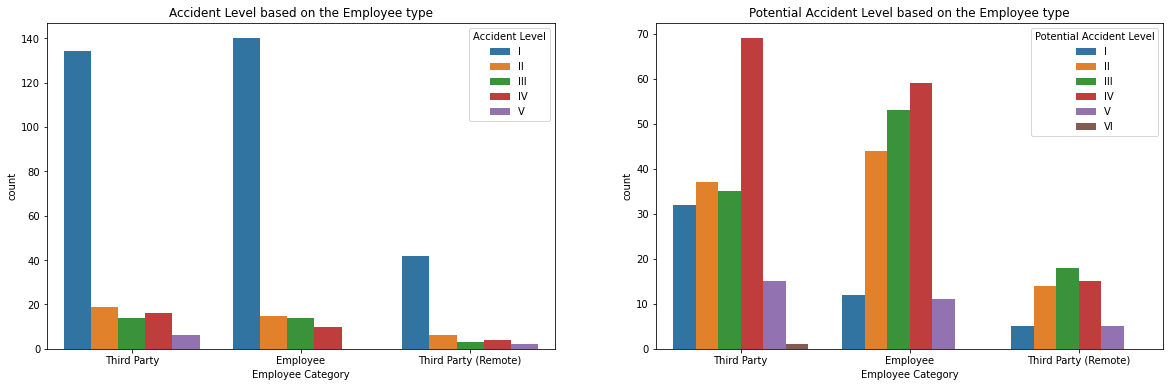

In [52]:
plt.figure(figsize=(20,6))
plt.subplot(1,2,1)
plt.title("Accident Level based on the Employee type")
sns.countplot(x="Employee Category", data = safety_data, hue="Accident Level", hue_order=safety_data['Accident Level'].value_counts().sort_index().index)

plt.subplot(1,2,2)
plt.title("Potential Accident Level based on the Employee type")
sns.countplot(x="Employee Category", data = safety_data, hue="Potential Accident Level", hue_order=safety_data['Potential Accident Level'].value_counts().sort_index().index)



*   Third Party Employees are more occured in Potential Accidents
*   In the accidents, Employees and thrid party are more involved.



##Accident Levels and Potential Accident Levels by Month

<AxesSubplot:title={'center':'Potential Accident Level based on the Month'}, xlabel='Month', ylabel='count'>

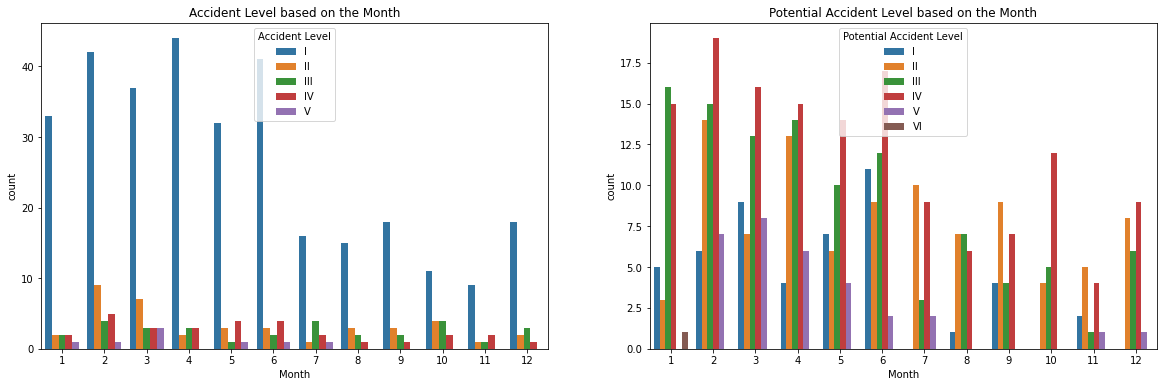

In [53]:
plt.figure(figsize=(20,6))
plt.subplot(1,2,1)
plt.title("Accident Level based on the Month")
sns.countplot(x="Month", data = safety_data, hue="Accident Level", hue_order=safety_data['Accident Level'].value_counts().sort_index().index)

plt.subplot(1,2,2)
plt.title("Potential Accident Level based on the Month")
sns.countplot(x="Month", data = safety_data, hue="Potential Accident Level", hue_order=safety_data['Potential Accident Level'].value_counts().sort_index().index)

* Beginning of the year get more accident 
* Accident Level occured more at Level 1 and Potential Accident occured more at Level 4

##Accident Level vs potential Accident Level

In [54]:
accident = safety_data['Accident Level'].value_counts()
potential = safety_data['Potential Accident Level'].value_counts()

acc_pot = pd.concat([accident, potential], axis=1,sort=False).fillna(0).reset_index()

acc_pot = pd.melt(acc_pot, ['index'], var_name='Accident type', value_name='count')
acc_pot

,index,Accident type,count
0,I,Accident Level,316.0
1,II,Accident Level,40.0
2,III,Accident Level,31.0
3,IV,Accident Level,30.0
4,V,Accident Level,8.0
5,VI,Accident Level,0.0
6,I,Potential Accident Level,49.0
7,II,Potential Accident Level,95.0
8,III,Potential Accident Level,106.0
9,IV,Potential Accident Level,143.0


###Multivariate Analysis

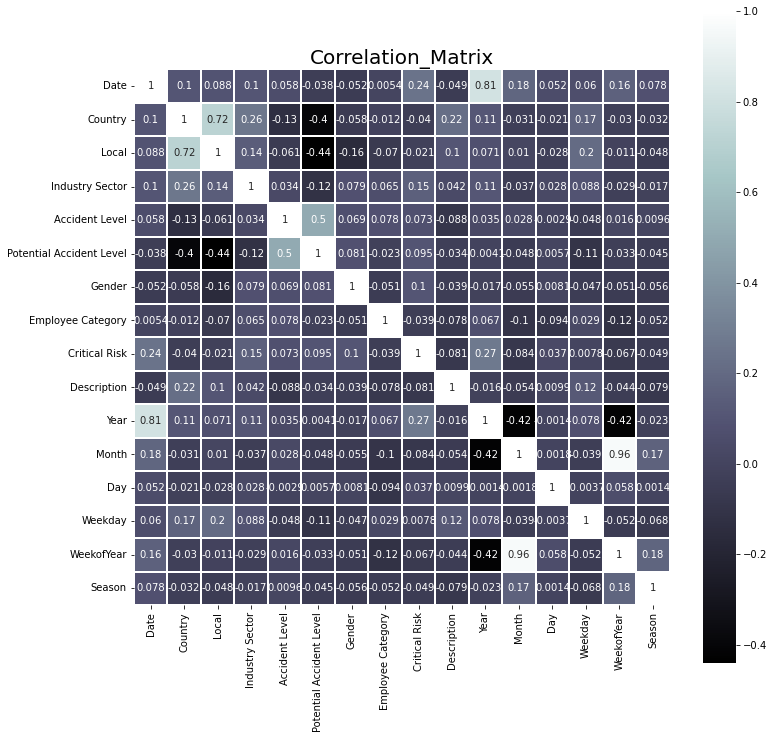

In [55]:
le = LabelEncoder()
safety_data_enc = safety_data.apply(le.fit_transform)

plt.figure(figsize=(12,12))
plt.title('Correlation_Matrix', fontsize=20)
sns.heatmap(safety_data_enc.corr(), square=True, cmap='bone', annot=True, linewidth=0.2);

## NLP Preprocessing

Few of the NLP pre-processing steps taken before applying model on the data

1. Converting to lower case, avoid any capital cases
2. Converting apostrophe to the standard lexicons
3. Removing punctuations
4. Lemmatization
5. Removing stop words

In [56]:
stopwords = stopwords.words('english')
def text_cleaning(text):
   # Initialize the object for Lemmatizer class
    lemmatizer = nltk.stem.WordNetLemmatizer()

    # Set the stopwords to English
    #stopwords = nltk.corpus.stopwords.words('english')

    # Normalize the text in order deal with accented words and unicodes
    text = (unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode('utf-8', 'ignore').lower())

    remove_punct_dict = dict((ord(punct), None) for punct in string.punctuation)
    #word tokenization
    words = nltk.word_tokenize(text.translate(remove_punct_dict))

    # Consider the words which are not in stopwords of english and lemmatize them
    lemmatizer = nltk.stem.WordNetLemmatizer()
    lems = [lemmatizer.lemmatize(i) for i in words if i not in stopwords]

    return lems

In [57]:
# Apply all the preprocessing techniques we have defined on Description columns
tokens = text_cleaning(' '.join(safety_data['Description'].sum().split()))

In [58]:
# Verifying by printing first 20 words
print('Length of all the words:', len(tokens),'\n')
print('Length of unique tokens in the dataset:', len(np.unique(tokens)),'\n')
np.array(tokens[0:20])

Length of all the words: 14677 

Length of unique tokens in the dataset: 3504 



array(['removing', 'drill', 'rod', 'jumbo', '08', 'maintenance',
       'supervisor', 'proceeds', 'loosen', 'support', 'intermediate',
       'centralizer', 'facilitate', 'removal', 'seeing', 'mechanic',
       'support', 'one', 'end', 'drill'], dtype='<U12')

In [59]:
safety_data['Cleaned_Description'] = safety_data.apply(lambda x: " ".join(text_cleaning(x.Description)), axis=1)

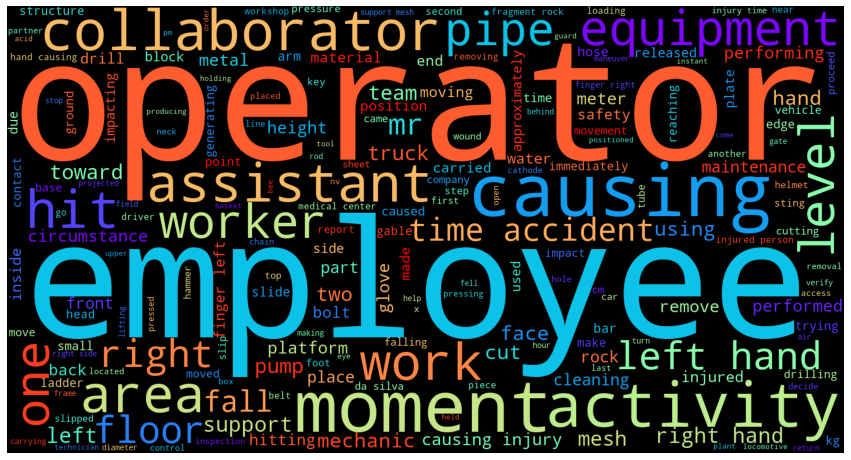

In [60]:
wordcloud = WordCloud(width = 1500, height = 800, 
                background_color='black', colormap='rainbow', 
                stopwords = stopwords,
                min_font_size = 10).generate(' '.join(tokens))

plt.figure(figsize = (15, 10), facecolor = 'white', edgecolor='blue') 
plt.imshow(wordcloud) 
plt.axis("off") 
  
plt.show()

**Observations**

There are many body-related, employee related, movement-related, equipment-related and accident-related words.

1. **Body-related:** left, right, hand, finger, face, foot and glove

2. **Employee-related:** employee, operator, collaborator, assistant, worker and mechanic

3. **Movement-related:** fall, hit, lift and slip

4. **Equipment-related:** equipment, pump, meter, drill, truck and tube

Lets work on the word cloud based in the Accident Levels

### Wordcloud for Accident Level - I

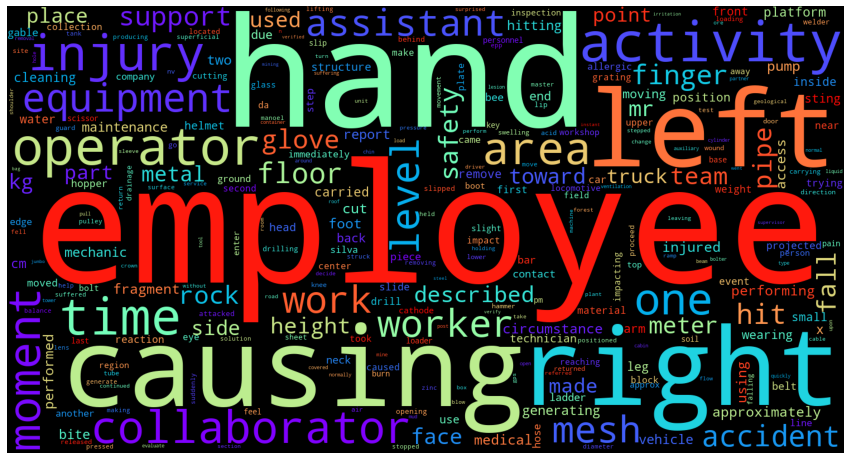

In [61]:
accidentLevel1 = safety_data[safety_data['Accident Level']== 'I']
accidentLevel1
wordcloud = WordCloud(width = 1500, height = 800, random_state=0, background_color='black', colormap='rainbow', \
                      min_font_size=5, max_words=300, collocations=False, stopwords = STOPWORDS).generate(' '.join(accidentLevel1['Cleaned_Description'].values))
plt.figure(figsize=(15,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

For the Accident level 1, the following are the most occured words

1. left hand right hand, finger, glove

2. employee, assistant, operator, worker

3. work area, floor

### Wordcloud for Accident Level - II

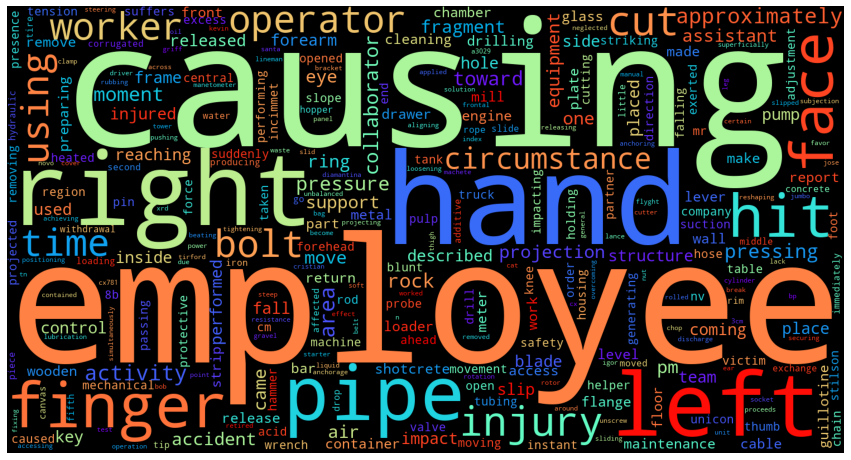

In [62]:
accidentLevel2 = safety_data[safety_data['Accident Level']== 'II']
accidentLevel2
wordcloud = WordCloud(width = 1500, height = 800, random_state=0, background_color='black', colormap='rainbow', \
                      min_font_size=5, max_words=300, collocations=False, stopwords = STOPWORDS).generate(" ".join(accidentLevel2['Cleaned_Description'].values))
plt.figure(figsize=(15,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

For the Accident level II, the following are the most occured words

1. right hand, finger, left, face

2. employee, operator, worker

3. **injury type:** like cut, hit

4. **injury by:** pipe, bolt

### Wordcloud for Accident Level - III

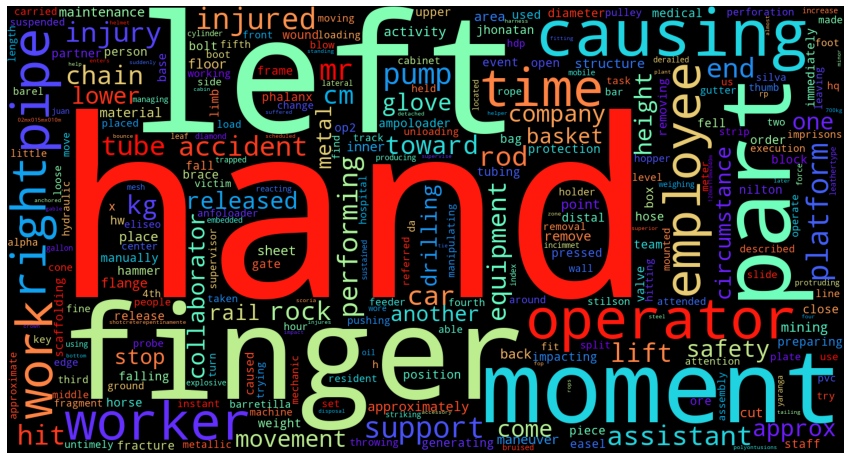

In [63]:
accidentLevel3 = safety_data[safety_data['Accident Level']== 'III']
accidentLevel3
wordcloud = WordCloud(width = 1500, height = 800, random_state=0, background_color='black', colormap='rainbow', \
                      min_font_size=5, max_words=300, collocations=False, stopwords = STOPWORDS).generate(" ".join(accidentLevel3['Cleaned_Description'].values))
plt.figure(figsize=(15,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

For the Accident level III, the following are the most occured words

1. right hand, finger, left, face

2. employee, worker, assistant

3. **injury type:** like hit

4. **injury by:** pipe, bolt, pump, piece of metal
time and circumstance

### Wordcloud for Accident Level - IV

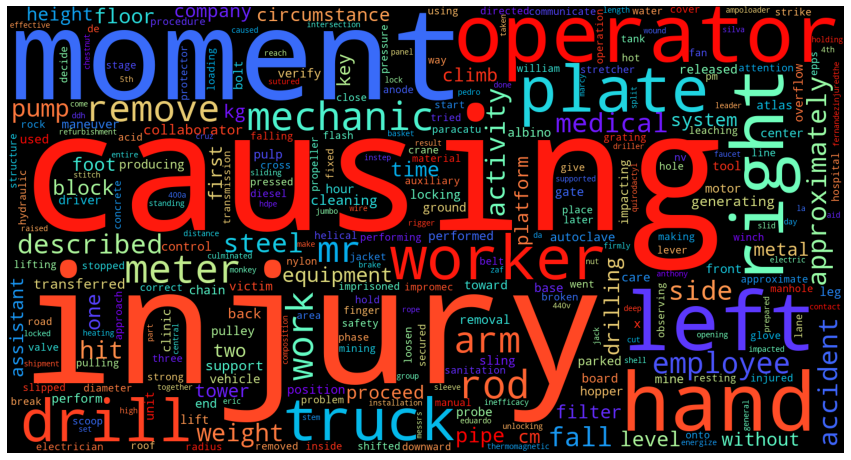

In [64]:
accidentLevel4 = safety_data[safety_data['Accident Level']== 'IV']
accidentLevel4
wordcloud = WordCloud(width = 1500, height = 800, random_state=0, background_color='black', colormap='rainbow', \
                      min_font_size=5, max_words=300, collocations=False, stopwords = STOPWORDS).generate(" ".join(accidentLevel4['Cleaned_Description'].values))
plt.figure(figsize=(15,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

For the Accident level IV, the following are the most occured words

right hand, finger, left, face, arm
employee, worker, operator

**injury type:** hit

**injury by:** pipe, bolt, pump, rod, drill , truck

### Wordcloud for Accident Level - V

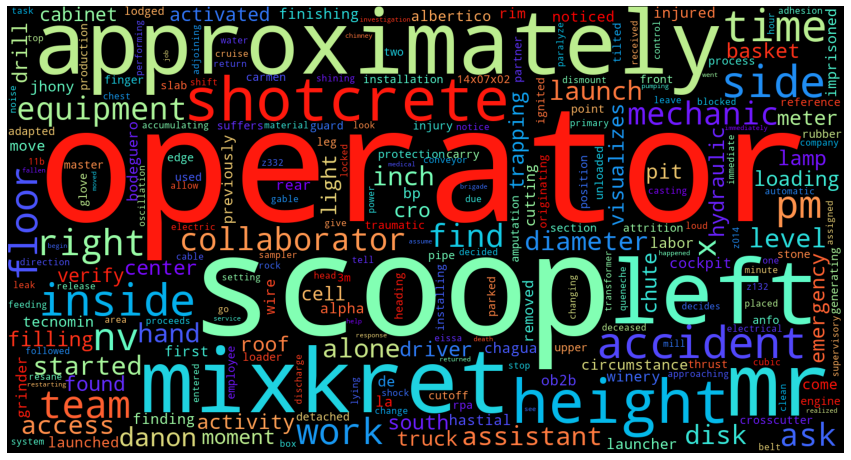

In [65]:
accidentLevel5 = safety_data[safety_data['Accident Level']== 'V']
accidentLevel5
wordcloud = WordCloud(width = 1500, height = 800, random_state=0, background_color='black', colormap='rainbow', \
                      min_font_size=5, max_words=300, collocations=False, stopwords = STOPWORDS).generate(" ".join(accidentLevel5['Cleaned_Description'].values))
plt.figure(figsize=(15,10))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

For the Accident level V, the following are the most occured words
right hand, finger, left, face
assistant, mechanic, operator
injury type: like hit
injury by: pipe, bolt, pump, piece of metal
shotcrete, mixkret,height, scoop

## Feature Engineering

In [66]:
safety_feature_data=safety_data.copy()

### Observation
Grouping the accident level based on the severity. Grouping accident level I and II as low level in a group, Level 3 as medium, Level 4 and 5 in a grp as High

In [67]:
safety_feature_data['AccidentLevel_grp'] = safety_data['Accident Level'].replace('II','I')
safety_feature_data['AccidentLevel_grp'] = safety_feature_data['AccidentLevel_grp'].replace('III','II').replace('IV','III').replace('V','III')
safety_feature_data['AccidentLevel_grp'].value_counts()

I      356
III     38
II      31
Name: AccidentLevel_grp, dtype: int64

### Label Encoding

In [68]:
safety_feature_data['Country'] = LabelEncoder().fit_transform(safety_feature_data['Country']).astype(np.int8)
safety_feature_data['Local'] = LabelEncoder().fit_transform(safety_feature_data['Local']).astype(np.int8)
safety_feature_data['Industry Sector'] = LabelEncoder().fit_transform(safety_feature_data['Industry Sector']).astype(np.int8)
safety_feature_data['AccidentLevel_grp'] = LabelEncoder().fit_transform(safety_feature_data['AccidentLevel_grp']).astype(np.int8)
safety_feature_data['Potential Accident Level'] = LabelEncoder().fit_transform(safety_feature_data['Potential Accident Level']).astype(np.int8)
safety_feature_data['Gender'] = LabelEncoder().fit_transform(safety_feature_data['Gender']).astype(np.int8)
safety_feature_data['Employee Category'] = LabelEncoder().fit_transform(safety_feature_data['Employee Category']).astype(np.int8)
safety_feature_data['Critical Risk'] = LabelEncoder().fit_transform(safety_feature_data['Critical Risk']).astype(np.int8)
safety_feature_data['Weekday'] = LabelEncoder().fit_transform(safety_feature_data['Weekday']).astype(np.int8)
safety_feature_data['Season'] = LabelEncoder().fit_transform(safety_feature_data['Season']).astype(np.int8)
safety_feature_data.drop(['Date','Accident Level','Description','Cleaned_Description'],inplace=True,axis=1)

In [69]:
safety_feature_data.head()

,Country,Local,Industry Sector,Potential Accident Level,Gender,Employee Category,Critical Risk,Year,Month,Day,Weekday,WeekofYear,Season,AccidentLevel_grp
0,0,0,1,3,1,1,20,2016,1,1,0,53,2,0
1,1,1,1,3,1,0,21,2016,1,2,2,53,2,0
2,0,2,1,2,1,2,15,2016,1,6,6,1,2,0
3,0,3,1,0,1,1,16,2016,1,8,0,1,2,0
4,0,3,1,3,1,1,16,2016,1,10,3,1,2,2


# Model Building

Segregating predictors vs target attribute

In [70]:
X = safety_feature_data.drop(labels= ['Potential Accident Level'] , axis = 1)
y = safety_feature_data["Potential Accident Level"]
X.head()

,Country,Local,Industry Sector,Gender,Employee Category,Critical Risk,Year,Month,Day,Weekday,WeekofYear,Season,AccidentLevel_grp
0,0,0,1,1,1,20,2016,1,1,0,53,2,0
1,1,1,1,1,0,21,2016,1,2,2,53,2,0
2,0,2,1,1,2,15,2016,1,6,6,1,2,0
3,0,3,1,1,1,16,2016,1,8,0,1,2,0
4,0,3,1,1,1,16,2016,1,10,3,1,2,2


Scaling the data

In [71]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from scipy.stats import zscore

In [72]:
hsdata_safety_feature_data_scaled  = X.apply(zscore) 

hsdata_safety_feature_data_scaled.describe()

,Country,Local,Industry Sector,Gender,Employee Category,Critical Risk,Year,Month,Day,Weekday,WeekofYear,Season,AccidentLevel_grp
count,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02,4.250000e+02
mean,-5.600749e-16,9.417304e-17,-1.191204e-16,1.128509e-16,3.004133e-18,-6.110145e-16,1.518670e-13,4.806613e-17,3.004133e-17,5.701322e-17,-2.024524e-16,-2.382408e-16,-8.489941e-17
std,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00,1.001179e+00
min,-7.588590e-01,-1.348476e+00,-1.278454e+00,-4.279975e+00,-1.036748e+00,-2.477938e+00,-7.008766e-01,-1.335168e+00,-1.616161e+00,-1.549128e+00,-1.426079e+00,-1.194070e+00,-4.154721e-01
25%,-7.588590e-01,-6.262299e-01,-1.278454e+00,2.336463e-01,-1.036748e+00,-2.667550e-02,-7.008766e-01,-7.074618e-01,-8.069927e-01,-1.055590e+00,-8.543694e-01,-1.194070e+00,-4.154721e-01
50%,-7.588590e-01,-2.651068e-01,3.149272e-01,2.336463e-01,4.174363e-01,-2.667550e-02,-7.008766e-01,-7.975562e-02,2.175915e-03,-6.851467e-02,-2.111962e-01,5.088821e-01,-4.154721e-01
75%,7.205680e-01,4.571394e-01,3.149272e-01,2.336463e-01,4.174363e-01,-2.667550e-02,1.426785e+00,5.479506e-01,8.113445e-01,9.185610e-01,6.463681e-01,5.088821e-01,-4.154721e-01
max,2.199995e+00,2.623878e+00,1.908309e+00,2.336463e-01,1.871620e+00,2.424587e+00,1.426785e+00,2.117216e+00,1.851704e+00,1.412099e+00,2.290033e+00,1.360358e+00,2.885007e+00


## **TF-IDF**

In [73]:
safety_tfidf_df = pd.DataFrame()
for i in [1,2,3]:
    vec_tfidf = TfidfVectorizer(max_features=10, norm='l2', stop_words='english', lowercase=True, use_idf=True, ngram_range=(i,i))
    X = vec_tfidf.fit_transform(safety_data['Cleaned_Description']).toarray()
    tfs = pd.DataFrame(X, columns=["TFIDF_" + n for n in vec_tfidf.get_feature_names()])
    safety_tfidf_df = pd.concat([safety_tfidf_df.reset_index(drop=True), tfs.reset_index(drop=True)], axis=1)

safety_tfidf_df.head(3)

,TFIDF_activity,TFIDF_causing,TFIDF_employee,TFIDF_hand,TFIDF_injury,TFIDF_left,TFIDF_moment,TFIDF_operator,TFIDF_right,TFIDF_time,...,TFIDF_causing injury described,TFIDF_described time accident,TFIDF_finger left hand,TFIDF_finger right hand,TFIDF_generating described injury,TFIDF_hand causing injury,TFIDF_injury time accident,TFIDF_left hand causing,TFIDF_manoel da silva,TFIDF_time accident employee
0,0.0,0.000000,0.0,0.645352,0.000000,0.000000,0.763885,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.469521,0.0,0.488204,0.548883,0.489831,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [74]:
##Combine TFIDF and Encoded Features
safety_feat_df = safety_feature_data.join(safety_tfidf_df.reset_index(drop=True))
safety_feat_df.head(3)

,Country,Local,Industry Sector,Potential Accident Level,Gender,Employee Category,Critical Risk,Year,Month,Day,...,TFIDF_causing injury described,TFIDF_described time accident,TFIDF_finger left hand,TFIDF_finger right hand,TFIDF_generating described injury,TFIDF_hand causing injury,TFIDF_injury time accident,TFIDF_left hand causing,TFIDF_manoel da silva,TFIDF_time accident employee
0,0,0,1,3,1,1,20,2016,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,1,3,1,0,21,2016,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,2,1,2,1,2,15,2016,1,6,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [75]:
X = safety_feature_data.drop(['AccidentLevel_grp','Potential Accident Level'],axis=1)
y = safety_feature_data['AccidentLevel_grp']

Train Test split

In [76]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42,stratify = y)

In [77]:
print(f'Training utterances: {X_train.shape}')
print(f'Validation utterances: {X_test.shape}')
print(f'Shape of Y: {y_train.shape}')
print(f'Shape of Y Test: {y_test.shape}')

Training utterances: (340, 12)
Validation utterances: (85, 12)
Shape of Y: (340,)
Shape of Y Test: (85,)


### Creating the models

#### Naive Bayes

In [78]:
X_nb = safety_data['Description']
y_nb = safety_data['Accident Level']
X_train_nb, X_test_nb, y_train_nb, y_test_nb = train_test_split(X_nb, y_nb, random_state=1)
vect = CountVectorizer()
vect.fit(X_train_nb)

# 4. transform training data
X_train_dtm = vect.transform(X_train_nb)
X_test_dtm = vect.transform(X_test_nb)
nb = MultinomialNB()
nb.fit(X_train_dtm, y_train_nb)
y_pred_class = nb.predict(X_test_dtm)
print("Accuracy Score",accuracy_score(y_test_nb, y_pred_class))
confusion_matrix(y_test_nb, y_pred_class)

Accuracy Score 0.7663551401869159


array([[82,  0,  1,  0,  0],
       [ 7,  0,  0,  0,  0],
       [ 7,  0,  0,  0,  0],
       [ 7,  0,  0,  0,  0],
       [ 3,  0,  0,  0,  0]])

In [79]:
def ml_models(Xtrain , ytrain, Xtest, ytest):

    # creating a dictionary with different ML models
    models = {
        'NaiveBayes' : GaussianNB(),
        'LogisticReg': LogisticRegression(solver='lbfgs', multi_class='multinomial', random_state = 1), 
        'KNN': KNeighborsClassifier(),        
        'SVM': SVC(kernel = 'rbf', probability=True), 
        'Decision Tree': DecisionTreeClassifier(criterion='entropy',max_depth=6,random_state=100,min_samples_leaf=5),          
        'RandomForest': RandomForestClassifier(n_estimators=50, max_depth=7),
        'Bagging': BaggingClassifier(n_estimators=30, max_samples=0.75, random_state=1, oob_score=True),
        'AdaBoost': AdaBoostClassifier(n_estimators=100, learning_rate=0.25, random_state=1),
        'Gradient Boost': GradientBoostingClassifier(loss='deviance', n_estimators=50, learning_rate=0.1, validation_fraction=0.2, 
                                       random_state=1),
        'XGBoost': XGBClassifier(min_child_weight = 7, max_depth = 6, objective="multi:softmax", learning_rate = 0.1, gamma = 0.4, 
                                       colsample_bytree = 0.5)
    }
    
    names = []
    Test_accuracy = []
    Train_accuracy = []
    prec_result = []
    recall_result = []
    f1result = []


    for name, model in models.items(): # Looping through each and every model
        clf = model.fit(Xtrain, ytrain) # Fit the models one by one
        test_acc = clf.score(Xtest,ytest)
        train_acc = clf.score(Xtrain, ytrain)
        y_pred = model.predict(Xtest)
        precisionscore = precision_score(ytest, y_pred, average='weighted')
        recallscore = recall_score(ytest, y_pred, average='weighted')
        f1score = f1_score(ytest, y_pred, average='weighted')
        names.append(name)
        Test_accuracy.append(test_acc) # Appending the test scores to the list
        Train_accuracy.append(train_acc)# Appending the training scores to the list
        prec_result.append(precisionscore)
        recall_result.append(recallscore)
        f1result.append(f1score)

        result_df =  pd.DataFrame({'model': names, 'Test_accuracy': Test_accuracy,'Train_accuracy':Train_accuracy,'Precision':prec_result,'Recall':recall_result,'F1_score':f1result}) # Creating the dataframe using the model scores
      
    return result_df # Returns the dataframe

### Running the models with TF-IDF vectorization

In [80]:
ml_models(X_train, y_train, X_test, y_test)

[01:44:07] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1645117948562/work/src/learner.cc:1115: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'multi:softprob' was changed from 'merror' to 'mlogloss'. Explicitly set eval_metric if you'd like to restore the old behavior.


,model,Test_accuracy,Train_accuracy,Precision,Recall,F1_score
0,NaiveBayes,0.270588,0.217647,0.795992,0.270588,0.321312
1,LogisticReg,0.835294,0.838235,0.697716,0.835294,0.760332
2,KNN,0.811765,0.838235,0.694401,0.811765,0.748510
3,SVM,0.835294,0.838235,0.697716,0.835294,0.760332
4,Decision Tree,0.800000,0.844118,0.692683,0.800000,0.742484
5,RandomForest,0.835294,0.879412,0.697716,0.835294,0.760332
6,Bagging,0.811765,0.964706,0.724764,0.811765,0.763055
7,AdaBoost,0.823529,0.823529,0.696078,0.823529,0.754459
8,Gradient Boost,0.835294,0.905882,0.798583,0.835294,0.780273
9,XGBoost,0.835294,0.864706,0.697716,0.835294,0.760332


Variable Creation - Word2Vec Embeddings

In [81]:
# define training data
# sentences = safety_data['Cleaned_Description']

# train model
# model = Word2Vec(sentences, min_count=1)

# summarize the loaded model
# print(model)

# summarize vocabulary
# words = list(model.wv.index2word)
            #  wv.index_to_key)
# print(words)

# save model
# model.save('model.bin')

# load model
# new_model = Word2Vec.load('model.bin')
# print(new_model)

Word2Vec(vocab=37, vector_size=100, alpha=0.025)


AttributeError: The index2word attribute has been replaced by index_to_key since Gensim 4.0.0.
See https://github.com/RaRe-Technologies/gensim/wiki/Migrating-from-Gensim-3.x-to-4

Variable Creation - Glove Word Embeddings

In [82]:
embeddings_index = {}
EMBEDDING_FILE = file_path + 'glove.6B.100d.txt'
f = open(EMBEDDING_FILE)
for line in tqdm(f):
    values = line.split()
    word = values[0]
    coefs = np.asarray(values[1:], dtype='float32')
    embeddings_index[word] = coefs
f.close()

print('Found %s word vectors.' % len(embeddings_index))

NameError: name 'file_path' is not defined

In [83]:
# this function creates a normalized vector for the whole sentence
def sent2vec(s):
    words = str(s).lower()
    words = word_tokenize(words)
    words = [w for w in words if not w in stopwords]
    words = [w for w in words if w.isalpha()]
    M = []
    for w in words:
        try:
            M.append(embeddings_index[w])
        except:
            continue
    M = np.array(M)
    v = M.sum(axis=0)
    if type(v) != np.ndarray:
        return np.zeros(300)
    return v / np.sqrt((v ** 2).sum())

In [84]:
# create sentence GLOVE embeddings vectors using the above function for training and validation set
safety_glove_df = [sent2vec(x) for x in tqdm(safety_data['Cleaned_Description'])]

100%|██████████| 425/425 [00:00<00:00, 2814.33it/s]


In [85]:
safety_feat_glv = safety_feat_df.join(pd.DataFrame(safety_glove_df).iloc[:,0:30].reset_index(drop=True))
safety_feat_glv.head(3)

,Country,Local,Industry Sector,Potential Accident Level,Gender,Employee Category,Critical Risk,Year,Month,Day,...,20,21,22,23,24,25,26,27,28,29
0,0,0,1,3,1,1,20,2016,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,1,3,1,0,21,2016,1,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,2,1,2,1,2,15,2016,1,6,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Modelling with Glove embeddings

In [86]:
X_glv = safety_feat_glv.drop(['AccidentLevel_grp','Potential Accident Level'],axis=1)
y_glv = safety_feat_glv['AccidentLevel_grp']

In [87]:
X_train_glv, X_test_glv, y_train_glv, y_test_glv = train_test_split(X_glv,y_glv, test_size=0.2, random_state=42,stratify = y)

Running the ML models using the Glove embedding data

In [88]:
ml_models(X_train_glv, y_train_glv, X_test_glv, y_test_glv)

[01:45:57] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1645117948562/work/src/learner.cc:1115: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'multi:softprob' was changed from 'merror' to 'mlogloss'. Explicitly set eval_metric if you'd like to restore the old behavior.


,model,Test_accuracy,Train_accuracy,Precision,Recall,F1_score
0,NaiveBayes,0.200000,0.232353,0.786553,0.200000,0.262936
1,LogisticReg,0.835294,0.838235,0.697716,0.835294,0.760332
2,KNN,0.811765,0.841176,0.694401,0.811765,0.748510
3,SVM,0.835294,0.838235,0.697716,0.835294,0.760332
4,Decision Tree,0.811765,0.841176,0.731943,0.811765,0.769725
5,RandomForest,0.835294,0.888235,0.697716,0.835294,0.760332
6,Bagging,0.788235,0.970588,0.699559,0.788235,0.741254
7,AdaBoost,0.823529,0.811765,0.755735,0.823529,0.781028
8,Gradient Boost,0.800000,0.958824,0.779002,0.800000,0.766364
9,XGBoost,0.800000,0.914706,0.701235,0.800000,0.747368


SMOTE

SMOTE - Generate synthetic samples - upsample smaller class

Applying smote for the train data and running the model in TFidf vector data

In [89]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=1)
X_train_smt, y_train_smt=smote.fit_resample(X_train, y_train) 

ModuleNotFoundError: No module named 'imblearn'

In [ ]:
y_train.value_counts()

0    285
2     30
1     25
Name: AccidentLevel_grp, dtype: int64

In [ ]:
y_train_smt.value_counts()

0    285
2    285
1    285
Name: AccidentLevel_grp, dtype: int64

Running the ML Models after applying Smote sampling

In [ ]:
ml_models(X_train_smt, y_train_smt, X_test, y_test)

,model,Test_accuracy,Train_accuracy,Precision,Recall,F1_score
0,NaiveBayes,0.364706,0.440936,0.783688,0.364706,0.444098
1,LogisticReg,0.482353,0.541520,0.752104,0.482353,0.565324
2,KNN,0.400000,0.852632,0.691334,0.400000,0.485703
3,SVM,0.129412,0.443275,0.849542,0.129412,0.113389
4,Decision Tree,0.564706,0.809357,0.749372,0.564706,0.639252
5,RandomForest,0.729412,0.945029,0.753617,0.729412,0.740678
6,Bagging,0.705882,0.997661,0.705882,0.705882,0.705882
7,AdaBoost,0.647059,0.709942,0.777574,0.647059,0.694593
8,Gradient Boost,0.682353,0.918129,0.708393,0.682353,0.694415
9,XGBoost,0.717647,0.973099,0.722857,0.717647,0.719955


After running the model with smote sampling,

1. The test accuracy got reduced and the train accuracy increased to most of the models.

2. There is much variation in Precision and recall score. But the F1 score is not much changed for the models

3. From Above models, it shows that, Adaboost, logistic Regression and SVM did the good performance.

We can do hyper parameter tuning to check for accuracy and scores

Hyper Parameter Tuning



In [ ]:
param_range = [2,3,4,5]
param_range_fl = [1.0, 0.5, 0.1]
param_depth=[3, 4, 5, 6]
learning_rt=[0.001, 0.01, 0.1]

In [ ]:
#### Specifying hyperparameters for all models
grid_params_nb = {
    'var_smoothing': np.logspace(0,-9, num=100)
}

grid_params_lr = [{'penalty': ['l1', 'l2'],
                   'C': param_range_fl,
                   'solver': ['liblinear','lbfgs']}]

grid_params_knn = [{'algorithm': ['kd_tree','brute'],
                    'n_neighbors': range(3, 21, 2),
                    'leaf_size': param_range,
                    'metric':['euclidean','minkowski']}]


grid_params_svm = [{'kernel': ['linear', 'rbf'], 
                    'C': param_range,
                    'gamma': ['scale']}]

grid_params_dt = [{'criterion': ['gini', 'entropy'],
                'min_samples_leaf': param_range,
                'max_depth': param_depth,
                'min_samples_split': param_range[1:]}]

grid_params_rf = [{'criterion': ['gini', 'entropy'],
                   'min_samples_leaf': param_range,
                   'max_depth': param_depth,
                   'min_samples_split': param_range[1:]}]
            
grid_params_bag = [{'n_estimators': [10, 100, 1000],
                   'max_samples': param_range}]

grid_params_adabst =[{'n_estimators': np.arange(30,100,10),
                 'learning_rate': np.arange(0.1,1,0.5)}]

grid_params_gb = [{'criterion': ['friedman_mse','mse'],
              'learning_rate': learning_rt,
              'max_depth': param_depth,
              'min_samples_split': param_range[1:]}]

grid_params_xgb = [{'learning_rate': [0.05, 0.10, 0.15],
                  'max_depth' : [3, 4, 6],
                  'min_child_weight': [ 3, 5],
                  'gamma': [0.1, 0.2 , 0.3],
                  'objective': ['multi:softmax']}]

In [ ]:
#### Specifying grid search for all models
grdsrch_nb = GridSearchCV(estimator=GaussianNB(),
                          param_grid=grid_params_nb, 
                          verbose=1, cv=10, n_jobs=-1)

grdsrch_lr = GridSearchCV(estimator=LogisticRegression(),
                       param_grid=grid_params_lr,
                       scoring='accuracy',
                       cv=10)

grdsrch_knn = GridSearchCV(estimator=KNeighborsClassifier(),
                          param_grid=grid_params_knn,
                          scoring='accuracy',
                          cv=10)

grdsrch_svm = GridSearchCV(estimator=SVC(),
                          param_grid=grid_params_svm,
                          scoring='accuracy',
                          cv=10)

grdsrch_dt = GridSearchCV(estimator=DecisionTreeClassifier(),
                          param_grid=grid_params_dt,
                          scoring='accuracy',
                          cv=10)

grdsrch_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42),
                          param_grid=grid_params_rf,
                          scoring='accuracy',
                          cv=10)

grdsrch_bag = GridSearchCV(estimator=BaggingClassifier(random_state=42),
                          param_grid=grid_params_bag,
                          scoring='accuracy',
                          cv=10)

grdsrch_ada = GridSearchCV(estimator=AdaBoostClassifier(random_state=42),
                          param_grid=grid_params_adabst,
                          scoring='accuracy',
                          cv=10)

grdsrch_gb = GridSearchCV(estimator=GradientBoostingClassifier(random_state=42),
                          param_grid=grid_params_gb,
                          scoring='accuracy',
                          cv=10)

grdsrch_xgb = GridSearchCV(estimator=XGBClassifier(random_state=42),
                          param_grid=grid_params_xgb,
                          scoring='accuracy',
                          cv=10)

In [ ]:
# List of pipelines for ease of iteration
grids = [grdsrch_lr,grdsrch_knn, grdsrch_svm, grdsrch_dt, grdsrch_rf, grdsrch_bag, grdsrch_ada, grdsrch_gb, grdsrch_xgb,grdsrch_nb]

# Dictionary of pipelines and classifier types for ease of reference
grid_dict = {0: 'Logistic Regression', 1: 'KNN' , 2: 'SVM', 3: 'DecisionTree', 4:'Random Forest',  5: 'Bagging', 6: 'AdaBoostClassifier',
              7:'GradientBoostingClassifier',8:'XGBClassifier',9:'grdsrch_nb'}

In [ ]:
def hypertune_models(Xtrain, ytrain, Xtest, ytest):
    
  import time
  # Fit the grid search objects
  print('Performing model optimizations...')
  best_acc = 0.0
  best_clf = 0
  best_gs = ''
  result=[]
  cm=[]
  start = time.time()

  modelname=[]
  best_params=[]
  best_score=[]
  testaccuracy=[]


  for idx, gs in enumerate(grids):
    print(idx)
    print(gs)
    print('\nEstimator: %s' % grid_dict[idx])
  #Fit grid search
    gs.fit(Xtrain, ytrain)
    # Best params
    print('Best params: %s' % gs.best_params_)
    # Best training data accuracy
    print('Best training accuracy: %.3f' % gs.best_score_)
    # Predict on test data with best params
    y_pred = gs.predict(Xtest)
    # Test data accuracy of model with best params
    acc_score = accuracy_score(ytest, y_pred)
    print('Test set accuracy score for best params: %.3f ' % acc_score)
    # Track best (highest test accuracy) model
    print('****************************************************************************')
    result.append(accuracy_score(ytest, y_pred))
    modelname.append(grid_dict[idx])
    best_params.append(gs.best_params_)
    best_score.append(gs.best_score_)
    testaccuracy.append(acc_score)
    results_data = pd.DataFrame({'model': modelname, 'Best_score':best_score,'best params_TestAccuracy_':testaccuracy,'best_params':best_params})
    if accuracy_score(ytest, y_pred) > best_acc:
      best_acc = accuracy_score(ytest, y_pred)
      best_gs = gs
      best_clf = idx
  print('\nClassifier with best test set accuracy: %s' % grid_dict[best_clf])
  

  end=time.time()
  print("Time to run in secs:",((end - start)/60))
  return results_data

Running the model with Hyperparameter Tuning

In [ ]:
#hypertune_models(X_train_glv, y_train_glv, X_test_glv, y_test_glv)

In [ ]:
#hypertune_models(X_train, y_train, X_test, y_test)

In [ ]:
log = LogisticRegression()
rnd = RandomForestClassifier(n_estimators=100)
ada = AdaBoostClassifier()
svm = SVC()
KNN = KNeighborsClassifier()
NB= GaussianNB(),
vot_soft = VotingClassifier(estimators=[('LR', log), ('RF', rnd), ('ADAB', ada),('KNN', KNN)], voting='soft', weights=[1,1,2,1])

vot_soft.fit(X_train, y_train)

VotingClassifier(estimators=[('LR', LogisticRegression()),
                             ('RF', RandomForestClassifier()),
                             ('ADAB', AdaBoostClassifier()),
                             ('KNN', KNeighborsClassifier())],
                 voting='soft', weights=[1, 1, 2, 1])

In [ ]:
data = []
def vot_models():
  for clf in (log, rnd, ada, KNN, vot_soft):
      clf.fit(X_train, y_train)
      y_pred = clf.predict(X_test)
      acc_score = accuracy_score(y_test, y_pred)
      data.append({'model': clf, 'Best_score':acc_score})


vot_models()
df = pd.DataFrame(data)
print(df)

                                               model  Best_score
0                               LogisticRegression()    0.835294
1  (DecisionTreeClassifier(max_features='auto', r...    0.811765
2  (DecisionTreeClassifier(max_depth=1, random_st...    0.752941
3                             KNeighborsClassifier()    0.811765
4  VotingClassifier(estimators=[('LR', LogisticRe...    0.835294


###Design, train and test Neural networks model

In [ ]:
# get the accuracy, precision, recall, f1 score from model
def get_classification_metrics(model, X_test, y_test, target_type):
  
  # predict probabilities for test set
  yhat_probs = model.predict(X_test, verbose=0) # Multiclass

  # predict crisp classes for test set
  if target_type == 'multi_class':
    yhat_classes = model.predict_classes(X_test, verbose=0) # Multiclass
  else:
    yhat_classes = (np.asarray(model.predict(X_test))).round() # Multilabel

  # reduce to 1d array
  yhat_probs = yhat_probs[:, 0]

  # accuracy: (tp + tn) / (p + n)
  accuracy = accuracy_score(y_test, yhat_classes)

  # precision tp / (tp + fp)
  precision = precision_score(y_test, yhat_classes, average='micro')

  # recall: tp / (tp + fn)
  recall = recall_score(y_test, yhat_classes, average='micro')

  # f1: 2 tp / (2 tp + fp + fn)
  f1 = f1_score(y_test, yhat_classes, average='micro')

  return accuracy, precision, recall, f1

In [ ]:
class Metrics(keras.callbacks.Callback):

    def __init__(self, validation_data=()):
        super().__init__()
        self.validation_data = validation_data

    def on_train_begin(self, logs={}):
        self.val_f1s = []
        self.val_recalls = []
        self.val_precisions = []

    def on_epoch_end(self, epoch, logs={}):
        xVal, yVal, target_type = self.validation_data
        if target_type == 'multi_class':
          val_predict_classes = model.predict_classes(xVal, verbose=0) # Multiclass
        else:
          val_predict_classes = (np.asarray(self.model.predict(xVal))).round() # Multilabel
        
        
        val_targ = yVal

        _val_f1 = f1_score(val_targ, val_predict_classes, average='micro')
        _val_recall = recall_score(val_targ, val_predict_classes, average='micro')
        _val_precision = precision_score(val_targ, val_predict_classes, average='micro')
        self.val_f1s.append(_val_f1)
        self.val_recalls.append(_val_recall)
        self.val_precisions.append(_val_precision)
        return

In [ ]:
def nn_model():
    model = Sequential()
    
    model.add(Dense(50, input_dim=X_train_glv.shape[1], activation='relu', kernel_initializer='he_uniform'))
    model.add(Dense(100, activation='relu', kernel_initializer='he_uniform'))
    model.add(Dense(150, activation='relu', kernel_initializer='he_uniform'))
    model.add(Dense(40, activation='relu', kernel_initializer='he_uniform'))
    model.add(Dense(1, activation='linear'))

    # compile the keras model
    opt = optimizers.Adam(lr=1e-3)
    model.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
    
    return model

In [ ]:
model = nn_model()
# Use earlystopping
callback = keras.callbacks.EarlyStopping(monitor='loss', patience=5, min_delta=0.001)
rlrp = ReduceLROnPlateau(monitor='val_loss', factor=0.0001, patience=5, min_delta=1E-4)

# fit the keras model on the dataset
training_history = model.fit(X_train_glv, y_train_glv, epochs=100, batch_size=8, verbose=1, validation_data=(X_test_glv, y_test_glv), callbacks=[rlrp])

Epoch 1/100
43/43 [==============================] - 5s 12ms/step - loss: 2.9802e-08 - accuracy: 0.8382 - val_loss: 3.0854e-08 - val_accuracy: 0.8353 - lr: 0.0010
Epoch 2/100
43/43 [==============================] - 0s 6ms/step - loss: 2.9802e-08 - accuracy: 0.8382 - val_loss: 3.0854e-08 - val_accuracy: 0.8353 - lr: 0.0010
Epoch 3/100
43/43 [==============================] - 0s 6ms/step - loss: 2.9802e-08 - accuracy: 0.8382 - val_loss: 3.0854e-08 - val_accuracy: 0.8353 - lr: 0.0010
Epoch 4/100
43/43 [==============================] - 0s 6ms/step - loss: 2.9802e-08 - accuracy: 0.8382 - val_loss: 3.0854e-08 - val_accuracy: 0.8353 - lr: 0.0010
Epoch 5/100
43/43 [==============================] - 0s 6ms/step - loss: 2.9802e-08 - accuracy: 0.8382 - val_loss: 3.0854e-08 - val_accuracy: 0.8353 - lr: 0.0010
Epoch 6/100
43/43 [==============================] - 0s 5ms/step - loss: 2.9802e-08 - accuracy: 0.8382 - val_loss: 3.0854e-08 - val_accuracy: 0.8353 - lr: 0.0010
Epoch 7/100
43/43 [========

In [ ]:
# evaluate the keras model
_, accuracy = model.evaluate(X_test_glv, y_test_glv, batch_size=8, verbose=0)
print('Test accuracy: %.2f' % (accuracy*100))

Test accuracy: 83.53


Text(0.5, 1.0, 'Training and validation loss')

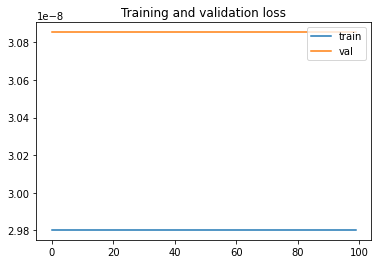

In [ ]:
epochs = range(len(training_history.history['loss'])) # Get number of epochs

# plot loss learning curves
plt.plot  (epochs, training_history.history['loss'], label = 'train')
plt.plot  (epochs, training_history.history['val_loss'], label = 'val')
plt.legend(loc = 'upper right')
plt.title ('Training and validation loss')

In [ ]:
# define the model
param = 1e-4
def batchnorm_model():
    model1 = Sequential()
    model1.add(Dense(50, input_dim=X_train_glv.shape[1], activation='relu'))
    model1.add(Dense(100, activation='relu'))
    model1.add(BatchNormalization())
    model1.add(Dropout(0.2))

    model1.add(Dense(150, activation='relu'))
    model1.add(BatchNormalization())
    model1.add(Dropout(0.2))
    model1.add(Dense(40, activation='relu'))
    model1.add(BatchNormalization())
    model1.add(Dropout(0.2))
    model1.add(Dense(1, activation='softmax'))

    # compile the keras model
    opt = optimizers.Adam(lr=1e-3)
    # opt = optimizers.SGD(lr=0.001, momentum=0.9)
    model1.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['accuracy'])
    
    return model1

In [ ]:
model_bat = batchnorm_model()
# Use earlystopping
callback = keras.callbacks.EarlyStopping(monitor='loss', patience=5, min_delta=0.001)
rlrp = ReduceLROnPlateau(monitor='val_loss', factor=0.0001, patience=5, min_delta=1E-4)

target_type = 'multi_label'
metrics = Metrics(validation_data=(X_train_glv, y_train_glv, target_type))

# fit the keras model on the dataset
training_history = model_bat.fit(X_train_glv, y_train_glv, epochs=100, batch_size=8, verbose=1, validation_data=(X_test_glv, y_test_glv), callbacks=[rlrp,metrics])

Epoch 1/100
43/43 [==============================] - 3s 24ms/step - loss: 0.0000e+00 - accuracy: 0.0735 - val_loss: 0.0000e+00 - val_accuracy: 0.0706 - lr: 0.0010
Epoch 2/100
43/43 [==============================] - 1s 12ms/step - loss: 0.0000e+00 - accuracy: 0.0735 - val_loss: 0.0000e+00 - val_accuracy: 0.0706 - lr: 0.0010
Epoch 3/100
43/43 [==============================] - 0s 12ms/step - loss: 0.0000e+00 - accuracy: 0.0735 - val_loss: 0.0000e+00 - val_accuracy: 0.0706 - lr: 0.0010
Epoch 4/100
43/43 [==============================] - 0s 11ms/step - loss: 0.0000e+00 - accuracy: 0.0735 - val_loss: 0.0000e+00 - val_accuracy: 0.0706 - lr: 0.0010
Epoch 5/100
43/43 [==============================] - 0s 11ms/step - loss: 0.0000e+00 - accuracy: 0.0735 - val_loss: 0.0000e+00 - val_accuracy: 0.0706 - lr: 0.0010
Epoch 6/100
43/43 [==============================] - 1s 13ms/step - loss: 0.0000e+00 - accuracy: 0.0735 - val_loss: 0.0000e+00 - val_accuracy: 0.0706 - lr: 0.0010
Epoch 7/100
43/43 [===

In [ ]:
_, train_accuracy = model_bat.evaluate(X_train_glv, y_train_glv, batch_size=8, verbose=0)
_, test_accuracy = model_bat.evaluate(X_test_glv, y_test_glv, batch_size=8, verbose=0)

print('Train accuracy: %.2f' % (train_accuracy*100))
print('Test accuracy: %.2f' % (test_accuracy*100))

Train accuracy: 7.35
Test accuracy: 7.06


In [ ]:
accuracy, precision, recall, f1 = get_classification_metrics(model_bat, X_test_glv, y_test_glv, target_type)
print('Accuracy: %f' % accuracy)
print('Precision: %f' % precision)
print('Recall: %f' % recall)
print('F1 score: %f' % f1)

Accuracy: 0.070588
Precision: 0.070588
Recall: 0.070588
F1 score: 0.070588


## LSTM classifiers


Creating a Model with Text Inputs Only

In [ ]:
X_text = safety_data['Cleaned_Description']
y_text = safety_feature_data['AccidentLevel_grp']

In [ ]:
# Encode labels in column 'Accident Level'.
y_text = LabelEncoder().fit_transform(y_text)

In [ ]:
# Divide our data into testing and training sets:
X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(X_text, y_text, test_size = 0.20, random_state = 1, stratify = y_text)

In [ ]:
print('X_text_train shape : ({0})'.format(X_text_train.shape))
print('y_text_train shape : ({0},)'.format(y_text_train.shape))
print('X_text_test shape : ({0})'.format(X_text_test.shape))
print('y_text_test shape : ({0},)'.format(y_text_test.shape))

X_text_train shape : ((340,))
y_text_train shape : ((340,),)
X_text_test shape : ((85,))
y_text_test shape : ((85,),)


In [ ]:
# Convert both the training and test labels into one-hot encoded vectors:
y_text_train = np_utils.to_categorical(y_text_train)
y_text_test = np_utils.to_categorical(y_text_test)

In [ ]:
# The first step in word embeddings is to convert the words into thier corresponding numeric indexes.
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(X_text_train)

X_text_train = tokenizer.texts_to_sequences(X_text_train)
X_text_test = tokenizer.texts_to_sequences(X_text_test)

In [ ]:
# Sentences can have different lengths, and therefore the sequences returned by the Tokenizer class also consist of variable lengths.
# We need to pad the our sequences using the max length.
vocab_size = len(tokenizer.word_index) + 1
print("vocab_size:", vocab_size)

maxlen = 100

X_text_train = pad_sequences(X_text_train, padding='post', maxlen=maxlen)
X_text_test = pad_sequences(X_text_test, padding='post', maxlen=maxlen)

vocab_size: 2839


In [ ]:
# We need to load the built-in GloVe word embeddings
embedding_size = 200
embeddings_dictionary = dict()

glove_file = open(file_path + 'glove.6B.200d.txt', encoding="utf8")

for line in glove_file:
    records = line.split()
    word = records[0]
    vector_dimensions = np.asarray(records[1:], dtype='float32')
    embeddings_dictionary[word] = vector_dimensions

glove_file.close()

embedding_matrix = np.zeros((vocab_size, embedding_size))

for word, index in tokenizer.word_index.items():
    embedding_vector = embeddings_dictionary.get(word)
    if embedding_vector is not None:
        embedding_matrix[index] = embedding_vector

len(embeddings_dictionary.values())

400000

In [ ]:
def lstm_model():

    # Build a LSTM Neural Network
    deep_inputs = Input(shape=(maxlen,))
    embedding_layer = Embedding(vocab_size, embedding_size, weights=[embedding_matrix], trainable=False)(deep_inputs)
    #### LSTM layer with Dropout regularisation
    LSTM_Layer_1 = Bidirectional(LSTM(128, return_sequences = True))(embedding_layer)
    max_pool_layer_1 = GlobalMaxPool1D()(LSTM_Layer_1)
    drop_out_layer_1 = Dropout(0.5, input_shape = (256,))(max_pool_layer_1)
    dense_layer_1 = Dense(128, activation = 'relu')(drop_out_layer_1)
    drop_out_layer_2 = Dropout(0.5, input_shape = (128,))(dense_layer_1)
    dense_layer_2 = Dense(64, activation = 'relu')(drop_out_layer_2)
    drop_out_layer_3 = Dropout(0.5, input_shape = (64,))(dense_layer_2)

    dense_layer_3 = Dense(32, activation = 'relu')(drop_out_layer_3)
    drop_out_layer_4 = Dropout(0.5, input_shape = (32,))(dense_layer_3)

    dense_layer_4 = Dense(10, activation = 'relu')(drop_out_layer_4)
    drop_out_layer_5 = Dropout(0.5, input_shape = (10,))(dense_layer_4)

    dense_layer_5 = Dense(3, activation='softmax')(drop_out_layer_5)

    modellstm = Model(inputs=deep_inputs, outputs=dense_layer_5) #As we have 3 ouputs we are inputting softmax with 3 outputs here
    
    ###SGD as optimiser
    opt = optimizers.SGD(lr=0.001, momentum=0.9)

    # compile the keras model
    modellstm.compile(loss='categorical_crossentropy', optimizer=opt, metrics=['acc'])
    
    return modellstm

In [ ]:
modellstm = lstm_model()
print(modellstm.summary())

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 100)]             0         
                                                                 
 embedding (Embedding)       (None, 100, 200)          567800    
                                                                 
 bidirectional (Bidirectiona  (None, 100, 256)         336896    
 l)                                                              
                                                                 
 global_max_pooling1d (Globa  (None, 256)              0         
 lMaxPooling1D)                                                  
                                                                 
 dropout_3 (Dropout)         (None, 256)               0         
                                                                 
 dense_10 (Dense)            (None, 128)               32896 

In [ ]:
# Use earlystopping
callback = keras.callbacks.EarlyStopping(monitor='loss', patience=7, min_delta=1E-3)
rlrp = ReduceLROnPlateau(monitor='val_loss', factor=0.0001, patience=5, min_delta=1E-4)

target_type = 'multi_label'
metrics = Metrics(validation_data=(X_text_train, y_text_train, target_type))

# fit the keras model on the dataset
training_history = modellstm.fit(X_text_train, y_text_train, epochs=100, batch_size=8, verbose=1, validation_data=(X_text_test, y_text_test), callbacks=[rlrp, metrics])

Epoch 1/100
43/43 [==============================] - 12s 120ms/step - loss: 1.0730 - acc: 0.5382 - val_loss: 0.8870 - val_acc: 0.8353 - lr: 0.0010
Epoch 2/100
43/43 [==============================] - 3s 64ms/step - loss: 0.8284 - acc: 0.7676 - val_loss: 0.7271 - val_acc: 0.8353 - lr: 0.0010
Epoch 3/100
43/43 [==============================] - 3s 64ms/step - loss: 0.6916 - acc: 0.8324 - val_loss: 0.6488 - val_acc: 0.8353 - lr: 0.0010
Epoch 4/100
43/43 [==============================] - 3s 66ms/step - loss: 0.6342 - acc: 0.8353 - val_loss: 0.6188 - val_acc: 0.8353 - lr: 0.0010
Epoch 5/100
43/43 [==============================] - 3s 63ms/step - loss: 0.6840 - acc: 0.8235 - val_loss: 0.6214 - val_acc: 0.8353 - lr: 0.0010
Epoch 6/100
43/43 [==============================] - 3s 65ms/step - loss: 0.6080 - acc: 0.8353 - val_loss: 0.6033 - val_acc: 0.8353 - lr: 0.0010
Epoch 7/100
43/43 [==============================] - 3s 66ms/step - loss: 0.6317 - acc: 0.8353 - val_loss: 0.5929 - val_acc: 0.8

In [ ]:
# evaluate the keras model
_, train_accuracy = modellstm.evaluate(X_text_train, y_text_train, batch_size=8, verbose=0)
_, test_accuracy = modellstm.evaluate(X_text_test, y_text_test, batch_size=8, verbose=0)

print('Train accuracy: %.2f' % (train_accuracy*100))
print('Test accuracy: %.2f' % (test_accuracy*100))

Train accuracy: 83.82
Test accuracy: 83.53


In [ ]:
accuracy, precision, recall, f1 = get_classification_metrics(modellstm, X_text_test, y_text_test, target_type)
print('Accuracy: %f' % accuracy)
print('Precision: %f' % precision)
print('Recall: %f' % recall)
print('F1 score: %f' % f1)

Accuracy: 0.835294
Precision: 0.835294
Recall: 0.835294
F1 score: 0.835294


Text(0.5, 1.0, 'Training and validation loss')

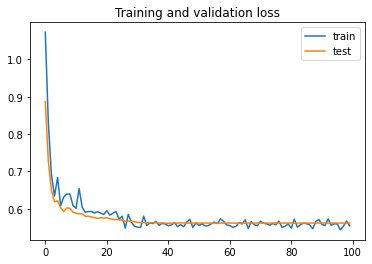

In [ ]:
epochs = range(len(training_history.history['loss'])) # Get number of epochs

# plot loss learning curves
plt.plot(epochs, training_history.history['loss'], label = 'train')
plt.plot(epochs, training_history.history['val_loss'], label = 'test')
plt.legend(loc = 'upper right')
plt.title ('Training and validation loss')

Text(0.5, 1.0, 'Training and validation accuracy')

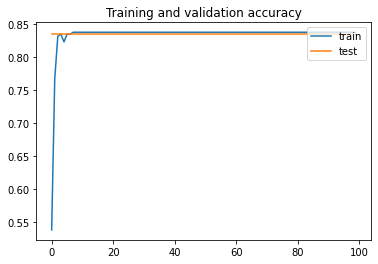

In [ ]:
# plot accuracy learning curves
plt.plot(epochs, training_history.history['acc'], label = 'train')
plt.plot(epochs, training_history.history['val_acc'], label = 'test')
plt.legend(loc = 'upper right')
plt.title ('Training and validation accuracy')

We could see it accuracy continually rise during training. As expected, we see the learning curves for accuracy on the test dataset plateau, indicating that the model has no longer overfit the training dataset and it is generalized model.

In [ ]:
  # Save the model in h5 format 
modellstm.save("model_lstm.h5")
print("Saved model to disk")

Saved model to disk


In [ ]:
yhat = modellstm.predict(X_text_test, verbose=0)
print(yhat)

[[0.8107105  0.08595565 0.1033338 ]
 [0.8063744  0.08798093 0.10564472]
 [0.8114559  0.08508579 0.10345833]
 [0.8074221  0.08738586 0.10519204]
 [0.8070375  0.0880252  0.10493739]
 [0.8113187  0.08547851 0.10320273]
 [0.80786014 0.08712044 0.10501943]
 [0.81117    0.08598751 0.10284244]
 [0.8126996  0.08515703 0.10214332]
 [0.806579   0.08846322 0.10495773]
 [0.8077834  0.08749437 0.10472219]
 [0.8109397  0.08590776 0.10315252]
 [0.809921   0.08585878 0.10422023]
 [0.8073645  0.08778908 0.10484643]
 [0.80692405 0.08804037 0.1050356 ]
 [0.80540144 0.08927381 0.10532475]
 [0.8085432  0.08711039 0.1043465 ]
 [0.8071486  0.08750337 0.10534802]
 [0.8082727  0.08779859 0.10392877]
 [0.8142829  0.08412065 0.10159649]
 [0.81233704 0.08483749 0.10282548]
 [0.8058204  0.08868002 0.10549962]
 [0.80910593 0.08730437 0.1035897 ]
 [0.80699974 0.08804037 0.10495987]
 [0.81107235 0.08512393 0.10380369]
 [0.8089218  0.0865631  0.10451511]
 [0.808527   0.08744316 0.10402982]
 [0.8060936  0.08902986 0.10

In [ ]:
def predict(msg):
  data = " ".join(text_cleaning(msg))

  #vectorizing the tweet by the pre-fitted tokenizer instance
  data = tokenizer.texts_to_sequences(data)
  #padding the tweet to have exactly the same shape as `embedding_2` input
  data = pad_sequences(data, maxlen=100, dtype='int32', value=0)
  ypred = modellstm.predict(data,batch_size=1,verbose = 2)[0]
  return ypred
  print(ypred)

In [ ]:
#msg = (safety_data['Description'][14])
msg = 'In moments that the operator of the Jumbo 2, tried energize your equipment to proceed to the installation of 4 split set at intersection 544 of Nv 3300, remove the lock and opening the electric board of 440V and 400A, and when lifting the thermomagnetic key This makes phase to ground - phase contact with the panel shell - producing a flash which reaches the operator causing the injury described.'
result=predict(msg)
result

278/278 - 3s - 3s/epoch - 10ms/step


array([0.8125258 , 0.08404454, 0.1034297 ], dtype=float32)

In [ ]:
class_label = np.argmax(result)
if class_label == 0:
  print('AccidentLevel I')
elif class_label == 1:
  print('AccidentLevel II')
else:
  print('AccidentLevel 1II')

AccidentLevel I
